# MedRelay on IBM LinuxONE - Hybrid GenAI + ML + Temporal Evidence Graphs for Clinical Follow-up Obligations

**Notebook mode:** controlled by the environment variable `MEDRELAY_MODE` (`fast` = development subset, `full` = every available record). Run all cells top to bottom from a clean kernel.

## 1. Project introduction and research questions

**Problem.** An instruction being *issued* is not the same as it being *fulfilled*. "Repeat the blood test within 48 hours, have the physician review the result, and contact the patient if further action is needed" is a **chain** of dependent obligations. A recorded blood test says nothing about whether the result was reviewed, or the patient told.

**Architecture (implemented in `src/`, orchestrated here):**

```
clinical text / events -> GenAI extraction (local Granite via llama.cpp) -> schema + evidence-grounding validation -> structured obligations
  -> supervised action classifier (cross-check) -> Temporal Evidence Graph (NetworkX, deterministic state rules)
  -> streaming event matching (SQLite, idempotent) -> calibrated ML risk (unresolved at deadline) -> constraint-based alerts + explanations -> audit log
```

**Research question.** Can dependency-aware temporal evidence graphs plus hybrid AI predict unresolved clinical obligations *earlier and more accurately* than conventional independent-task monitoring? *(A proposed contribution that needs experimental validation - not a claim of being first.)*

**What is real and what is not (read this first).**

| item | status |
|---|---|
| Hardware measurements, latencies, throughput | measured on the machine that executes this notebook (section 2 states its architecture) |
| Follow-up outcomes (completed / overdue / unverified / censored) | **simulated** by a seeded generator from documented source events; results are *performance on simulated follow-up processes only* |
| Action-classification labels | **weak (rule-proposed, "silver")**; **no human-reviewed (gold) labels exist** |
| Obligation-extraction evaluation sets | a **developer-annotated** challenge set (annotator = implementer, not independent) and **synthetic-by-construction** template documents |
| Appointment no-show data | real de-identified appointment records; label = attendance, *not* follow-up completion |
| Everything | synthetic or de-identified; **not clinically validated; recommendations require qualified human review** |

In [1]:
import os, sys, json, time, warnings, platform
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 100); pd.set_option("display.precision", 3)
from src.data_loader import load_config
cfg = load_config(); MODE = cfg["mode"]
T_NB0 = time.time()
print(f"MedRelay | mode={MODE} | seed={cfg['seed']} | python {platform.python_version()} | machine {platform.machine()} | cwd {ROOT}")

MedRelay | mode=fast | seed=20261017 | python 3.12.3 | machine s390x | cwd /home/linux1/medrelay-linuxone


## 2. IBM LinuxONE hardware verification

In [2]:
from src import benchmarks as bm
hw = bm.hardware_report()
slim = {k: v for k, v in hw.items() if k not in ("lscpu", "free_h", "df_h")}
Path("results").mkdir(exist_ok=True)
Path("results/hardware.json").write_text(json.dumps(slim, indent=2, default=str))
if hw["is_s390x"]:
    display(HTML("<div style='padding:8px;background:#e8f5e9;border-left:5px solid #2e7d32'><b>CONFIRMED:</b> this notebook is executing on IBM Z / LinuxONE "
                 f"(<code>uname -m</code> = <b>s390x</b>, {hw['byteorder']}-endian, hypervisor <b>{hw['hypervisor']}</b>).</div>"))
else:
    display(HTML(f"<div style='padding:8px;background:#ffebee;border-left:5px solid #c62828'><b>WARNING:</b> architecture is {hw['uname_m']}, not s390x. "
                 "Every measurement below comes from THIS machine and is NOT a LinuxONE result.</div>"))
print(hw["uname_a"]); print(); print(hw["lscpu"][:2200]); print("\n/proc/cpuinfo features:", hw["cpu_features"])
keys = ["uname_m", "byteorder", "nproc", "memory_total_gb", "memory_available_gb", "disk_total_gb", "disk_free_gb", "python", "hypervisor", "has_vxe2", "nnpa_cpu_flag", "nnpa_facility_165_listed", "docker", "podman"]
display(pd.DataFrame({"value": [slim[k] for k in keys]}, index=keys))
print(hw["free_h"]); print(hw["df_h"])

Linux medi 6.8.0-147-generic #147-Ubuntu SMP Thu Sep 24 10:59:43 UTC 2026 s390x s390x s390x GNU/Linux

Architecture:                            s390x
CPU op-mode(s):                          32-bit, 64-bit
Byte Order:                              Big Endian
CPU(s):                                  2
On-line CPU(s) list:                     0,1
Vendor ID:                               IBM/S390
Model name:                              -
Machine type:                            9175
Thread(s) per core:                      1
Core(s) per socket:                      1
Socket(s) per book:                      1
Book(s) per drawer:                      1
Drawer(s):                               2
CPU dynamic MHz:                         5508
CPU static MHz:                          5508
BogoMIPS:                                28901.00
Dispatching mode:                        horizontal
Flags:                                   esan3 zarch stfle msa ldisp eimm dfp edat etf3eh highgprs te vx v

,value
uname_m,s390x
byteorder,big
nproc,2
memory_total_gb,4.18
memory_available_gb,2.62
disk_total_gb,52.7
disk_free_gb,43.2
python,3.12.3
hypervisor,z/VM 7.3.0
has_vxe2,True


total        used        free      shared  buff/cache   available
Mem:           3.9Gi       1.4Gi       2.0Gi        12Mi       582Mi       2.4Gi
Swap:             0B          0B          0B
Filesystem      Size  Used Avail Use% Mounted on
/dev/dasda1      50G  6.9G   41G  15% /


In [3]:
nn = bm.nnpa_probe()
display(pd.DataFrame({"value": nn}).astype(str))
print("NNPA is PRESENT in the CPU flags/facility list" if nn["cpu_flag_nnpa"] else "NNPA flag not present on this host")
print("Presence is not use: tree/linear models (sklearn, XGBoost) do NOT run on NNPA. A device-level zDNN test is run in section 16.")

,value
cpu_flag_nnpa,True
docker,None
facility_165_listed,True
libzdnn,"['libzdnn.so.0 (libc6,64bit) => /lib/s390x-linux-gnu/libzdnn.so.0', '\tlibzdnn.so (libc6,64bit) ..."
libzdnn_installed,True
onnxruntime_available,False
podman,None
sklearn_uses_nnpa,False
xgboost_uses_nnpa,False
zdlc_note,IBM zDLC (onnx-mlir) is distributed as a container image; it needs podman/docker + registry access


NNPA is PRESENT in the CPU flags/facility list
Presence is not use: tree/linear models (sklearn, XGBoost) do NOT run on NNPA. A device-level zDNN test is run in section 16.


## 3. Environment and dependency configuration

In [4]:
from src.llm_backend import gguf_byteorder, host_byteorder
display(pd.DataFrame([{"package": k, "version": v} for k, v in hw["packages"].items()]))
mods = sorted((ROOT / cfg["llm"]["models_dir"]).glob("*.gguf"))
display(pd.DataFrame([{"model_file": m.name, "size_mb": round(m.stat().st_size / 1e6, 1), "gguf_byteorder": gguf_byteorder(m), "host_byteorder": host_byteorder(),
                       "usable_without_conversion": gguf_byteorder(m) == host_byteorder()} for m in mods]))
import llama_cpp
print("llama.cpp via llama-cpp-python", llama_cpp.__version__); print(llama_cpp.llama_print_system_info().decode())
print("\nSelected configuration (config.yaml):"); print(open("config.yaml").read())
print("Remote LLM backends:", "ENABLED" if cfg["llm"]["allow_remote"] else "disabled (all GenAI inference is local; no clinical text leaves this machine)")

,package,version
0,numpy,1.26.4
1,pandas,2.1.4
2,scipy,1.11.4
3,sklearn,1.4.1.post1
4,xgboost,2.0.3
5,networkx,2.8.8
6,pydantic,2.14.1
7,matplotlib,3.6.3
8,plotly,5.15.0
9,ipywidgets,8.1.1


,model_file,size_mb,gguf_byteorder,host_byteorder,usable_without_conversion
0,granite-4.0-1b-Q4_0.be.gguf,975.0,big,big,True
1,granite-4.0-350m-Q8_0.be.gguf,378.1,big,big,True


llama.cpp via llama-cpp-python 0.3.36
CPU : VXE = 1 | LLAMAFILE = 1 | OPENMP = 1 | REPACK = 1 | 

Selected configuration (config.yaml):
project: medrelay-linuxone
seed: 20261017
mode: fast                    # fast = development subset, full = every available record (override: env MEDRELAY_MODE)
paths:
  source: data/source         # uploaded outputs of the dataset-engineering pipeline (gzip CSV; pyarrow has no s390x wheel)
  processed: data/processed   # files derived on this machine (enriched event stream, manifests)
  models: models
  results: results
  figures: figures
  reports: reports
  db: results/medrelay_state.sqlite
data:
  fast: {patients_per_split: {train: 150, validation: 50, test: 80}}
  full: {patients_per_split: null}
stream:                       # delivery imperfections injected when the replay stream is built (deterministic)
  late_p: 0.06
  dup_p: 0.03
  late_obligation_p: 0.03
  late_hours: [2, 120]
engine:
  grace_hours: 12             # after a deadline, wait th

**Installation approach (see `docs/linuxone_setup.md`):** no Docker/Podman is required. Scientific Python comes from the distribution's precompiled `s390x` packages (PyPI has no `s390x`
wheel for NumPy/pandas/scikit-learn/pyarrow), `llama-cpp-python` is compiled from source for the z16 instruction set (VXE), Hugging Face GGUF files (little-endian) are converted once to
big-endian with `gguf-convert-endian`. Because `pyarrow` is unavailable, the dataset exports are consumed as gzip CSV.

## 4. Dataset loading and integrity validation

In [5]:
from src.data_loader import validate_datasets, build_stream, load_stream_truth
t = time.time()
rep = validate_datasets(cfg)
display(pd.DataFrame([{"check": k, "passed": v["ok"], "detail": str(v["detail"])[:120]} for k, v in rep["checks"].items()]))
print("hard failures:", rep["hard_failures"] or "none"); print("warnings:", *rep["warnings"], sep="\n  - ")
assert not rep["hard_failures"], rep["hard_failures"]
print("\nrecord counts:", rep["counts"]); print("validation took", round(time.time() - t, 1), "s")

,check,passed,detail
0,schema_interim,True,all required columns present
1,schema_risk_features,True,42 features + meta/labels present
2,schema_action,True,text/labels/tier/method/group present
3,schema_noshow,True,appointment columns present
4,missing_required,True,no nulls in required columns
5,unique_primary_keys,True,"{'obligations': 0, 'events': 0, 'patients': 0, 'action': 0, 'noshow': 0, 'nodes': 0, 'edges': 0}"
6,foreign_keys,True,"{'obligations->patients': 0, 'events->obligations': 0, 'depends_on->obligations': 0, 'encounters..."
7,split_assignment_consistent,True,"{'obligations': 0, 'risk_train': 0, 'action_train': 0, 'risk_validation': 0, 'action_validation'..."
8,patient_level_independence,True,"{'action': 0, 'noshow_patients': 0, 'risk': 0}"
9,sh_heldout_only_in_test,True,268 held-out Synthetic Hospital patients are test-only


hard failures: none
warnings:
  - no human-reviewed (gold) action labels: extraction/classification metrics against silver or developer-written sets are NOT clinical accuracy

record counts: {'patients': 3284, 'encounters': 11173, 'obligations': 24296, 'events': 34441, 'risk_rows': 12590, 'action_examples': 10002, 'noshow_rows': 110521, 'graph_nodes': 103627, 'graph_edges': 223925}
validation took 2.3 s


In [6]:
prov = rep["label_provenance"]
display(pd.DataFrame([{"dataset": "action classification", "label source": "weak rule-proposed (silver) + 622 train-only template (synthetic)", "human-reviewed gold": prov["gold_human_reviewed_action_labels"]},
                      {"dataset": "follow-up risk", "label source": prov["risk_labels"], "human-reviewed gold": 0},
                      {"dataset": "appointment no-show", "label source": prov["noshow_labels"], "human-reviewed gold": "n/a (real attendance record)"},
                      {"dataset": "evidence graph / event stream", "label source": "simulated scenario ground truth (hidden file, never in live payloads)", "human-reviewed gold": 0}]))
print("action label tiers:", prov["action_label_tiers"]); print("action label methods:", prov["action_label_methods"]); print("action sources:", prov["action_sources"])
cb = rep["class_balance"]
display(pd.DataFrame(cb["action"]).T.rename_axis("split")); display(pd.DataFrame(cb["risk_binary"]).T.rename_axis("split").rename(columns={"1": "overdue(1)", "0": "completed(0)"}))
display(pd.DataFrame(cb["risk_outcomes"]).T.rename_axis("split")); display(pd.DataFrame(cb["noshow"]).T.rename_axis("split"))

,dataset,label source,human-reviewed gold
0,action classification,weak rule-proposed (silver) + 622 train-only template (synthetic),0
1,follow-up risk,SIMULATED follow-up outcomes (generated scenarios); not clinically verified,0
2,appointment no-show,"REAL appointment attendance (Kaggle, de-identified); not follow-up completion",n/a (real attendance record)
3,evidence graph / event stream,"simulated scenario ground truth (hidden file, never in live payloads)",0


action label tiers: {'silver': 10002}
action label methods: {'rule_v1_negative_default': 6622, 'rule_v1': 2295, 'rule_v1_negative_historical': 626, 'synthea_template_rule': 459}
action sources: {'aci_bench': 3583, 'synthetic_hospital': 3043, 'mts_dialog': 2917, 'synthea': 459}


,appointment_referral,laboratory_test,imaging,procedure,medication_action,patient_communication,followup_review,other_action,no_action
split,,,,,,,,,
train,101,107,94,93,500,94,107,81,4532
validation,35,21,17,25,103,29,30,26,724
test,122,120,59,53,469,128,179,89,2283


,overdue(1),completed(0)
split,,
train,3732,2384
validation,1002,558
test,1578,1098


,overdue_unresolved,completed,unverified,censored_or_unknown
split,,,,
train,3732,2384,1072,280
validation,1002,558,246,72
test,1578,1098,466,102


,n,rate
split,,
train,77554.0,0.202
validation,16496.0,0.202
test,16471.0,0.203


In [7]:
from src.risk_predictor import build_graph_from_stream, feature_parity
from src.data_loader import subset_patients, read_source
pats = read_source(cfg, "interim/patients.csv.gz")
keep = subset_patients(cfg, pats)
t = time.time(); G0 = build_graph_from_stream(cfg, keep)
par = feature_parity(cfg, G0, sample=4000, patients=keep)
print("replay-stream graph:", G0.stats()); print("feature parity (graph recomputation vs dataset-pipeline tables):", par, "| %.1f s" % (time.time() - t))
assert par["exact_or_within_tolerance"], par
stream_paths = build_stream(cfg)
from collections import Counter
from src.data_loader import iter_stream
ev_counts, n_deliv, n_dup, n_late = Counter(), 0, 0, 0
from src.evidence_graph import to_epoch as _te
for ev_ in iter_stream(cfg):
    ev_counts[ev_["event_type"]] += 1; n_deliv += 1; n_dup += ev_["delivery_attempt"] > 1; n_late += (_te(ev_["ingest_time_utc"]) - _te(ev_["event_time_utc"])) > 7200
display(pd.DataFrame([ev_counts]).T.rename(columns={0: "deliveries"}).T)
an = pd.read_csv(stream_paths["anomalies"])
print("delivery imperfections injected into the replay stream:", an.anomalies.value_counts().to_dict(), "| deliveries:", n_deliv, "| duplicates:", n_dup, "| delayed >2h:", n_late)
del G0
import gc; gc.collect()

replay-stream graph: {'obligations': 2240, 'events_ingested': 8570, 'duplicates_ignored': 205, 'nx_nodes': 0, 'nx_edges': 0, 'rejected_cycles': 0, 'orphan_events_waiting': 0, 'unresolved_dependencies': 0}
feature parity (graph recomputation vs dataset-pipeline tables): {'rows_compared': 1175, 'features_compared': 42, 'mismatches': {}, 'exact_or_within_tolerance': True} | 0.9 s


,obligation_created,encounter_start,appointment_scheduled,appointment_rescheduled,deadline_reached,task_status_snapshot,reminder_sent,visit_no_show,result_posted,result_opened,visit_attended,contact_attempt,result_acknowledged,patient_notified,conflicting_record,appointment_cancelled,report_posted,imaging_order_documented,lab_collected,medication_dispensed,medication_opened,medication_acknowledged,imaging_performed,procedure_performed,consult_report_received,action_documented
deliveries,24985,11348,901,122,24296,4912,755,186,5250,7039,439,1263,4799,3057,549,35,2026,1916,172,618,640,472,107,91,60,19


delivery imperfections injected into the replay stream: {'late': 3461, 'duplicate': 2001} | deliveries: 96057 | duplicates: 2001 | delayed >2h: 3570


30764

## 5. Exploratory data analysis

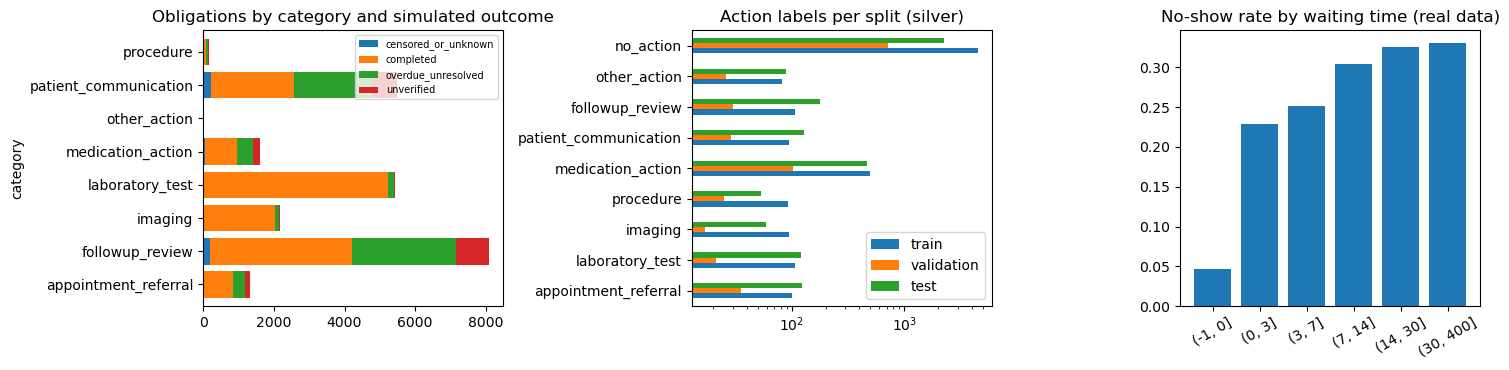

In [8]:
from src.data_loader import load_action, load_risk_hidden, load_noshow, load_interim
from src import visualization as viz
T = load_interim(cfg); A = load_action(cfg); NS = load_noshow(cfg); GT = load_stream_truth(cfg)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ct = pd.crosstab(T["obligations"].category, T["ground_truth"].set_index("obligation_id").loc[T["obligations"].obligation_id].outcome_label.values)
ct.plot(kind="barh", stacked=True, ax=ax[0], width=.8); ax[0].set_title("Obligations by category and simulated outcome"); ax[0].legend(fontsize=7)
act = pd.DataFrame({sp: A[sp][[c for c in A[sp].columns if c.startswith("y_")]].sum() for sp in ("train", "validation", "test")}); act.index = [i[2:] for i in act.index]
act.plot(kind="barh", ax=ax[1]); ax[1].set_title("Action labels per split (silver)"); ax[1].set_xscale("log")
ns = NS.assign(band=pd.cut(NS.wait_days, [-1, 0, 3, 7, 14, 30, 400])).groupby("band").no_show.agg(["mean", "size"])
ax[2].bar(ns.index.astype(str), ns["mean"]); ax[2].set_title("No-show rate by waiting time (real data)"); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); viz.save(fig, cfg, "eda_overview"); plt.show()

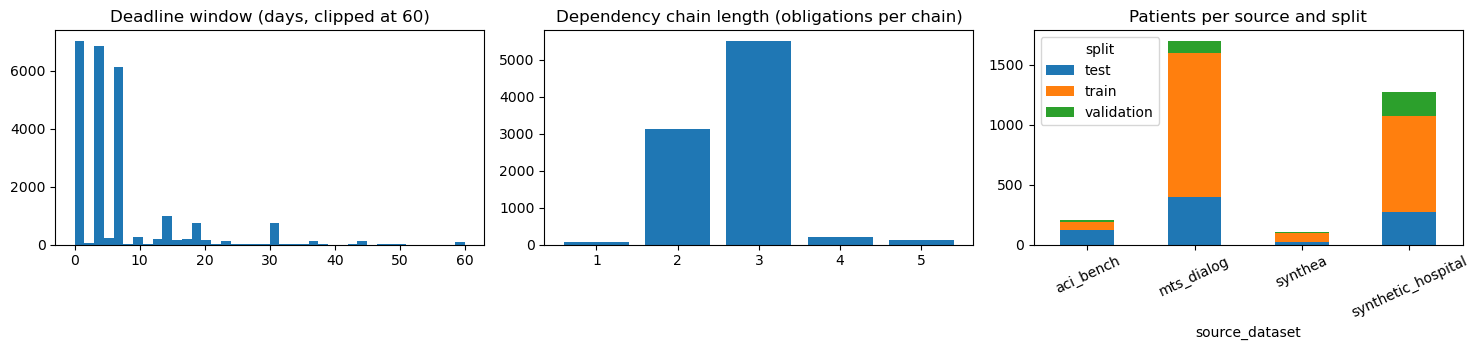

encounters: 11173 | patients: 3284 | obligations: 24296 | chains: 9037 | source events: 34441
share of obligations whose first step is a documented source event vs rule-extracted vs simulated:


seed_kind,documented_careplan,documented_lab_result,structured_order,text_extracted
obligations,698,13671,5122,4805


In [9]:
ob = T["obligations"]
win = (pd.to_datetime(ob.due_time_utc) - pd.to_datetime(ob.created_time_utc)).dt.total_seconds() / 86400
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(win.clip(upper=60), bins=40); ax[0].set_title("Deadline window (days, clipped at 60)")
depth = ob.groupby("chain_id").size().value_counts().sort_index(); ax[1].bar(depth.index.astype(str), depth.values); ax[1].set_title("Dependency chain length (obligations per chain)")
src = pd.concat([T["patients"].groupby(["source_dataset", "split"]).size().unstack(fill_value=0)]); src.plot(kind="bar", stacked=True, ax=ax[2]); ax[2].set_title("Patients per source and split"); ax[2].tick_params(axis="x", rotation=25)
plt.tight_layout(); viz.save(fig, cfg, "eda_structure"); plt.show()
print("encounters:", len(T["encounters"]), "| patients:", len(T["patients"]), "| obligations:", len(ob), "| chains:", ob.chain_id.nunique(), "| source events:", len(T["events"]))
print("share of obligations whose first step is a documented source event vs rule-extracted vs simulated:")
display(ob.groupby("seed_kind").size().rename("obligations").to_frame().T)
display(HTML("<i>Time precision: Synthetic Hospital dates are month-granular (all on the 15th); sub-day times are imputed. Synthea has clock times.</i>"))

## 6. Clinical obligation schema

In [10]:
import json as _json
from src.clinical_extractor import ExtractedObligation, EvidenceSpan
from src.ontology import STEP_SPEC, COMPLETION_EVENT, State, NODE_TYPES, EDGE_TYPES
sch = ExtractedObligation.model_json_schema()
print(_json.dumps({k: v for k, v in sch["properties"].items()}, indent=1)[:2600])
display(pd.DataFrame([{"workflow step": s, "category": c, "role": r, "completed only by event": COMPLETION_EVENT[s]} for s, (c, r) in STEP_SPEC.items()]))
display(pd.DataFrame([{"state": s.value} for s in State]).T)
print("graph node types:", NODE_TYPES); print("graph edge types:", EDGE_TYPES)

{
 "obligation_id": {
  "title": "Obligation Id",
  "type": "string"
 },
 "task_type": {
  "enum": [
   "appointment_referral",
   "laboratory_test",
   "imaging",
   "procedure",
   "medication_action",
   "patient_communication",
   "followup_review",
   "other_action"
  ],
  "title": "Task Type",
  "type": "string"
 },
 "description": {
  "maxLength": 400,
  "minLength": 3,
  "title": "Description",
  "type": "string"
 },
 "due_interval": {
  "anyOf": [
   {
    "type": "string"
   },
   {
    "type": "null"
   }
  ],
  "default": null,
  "title": "Due Interval"
 },
 "due_date": {
  "anyOf": [
   {
    "type": "string"
   },
   {
    "type": "null"
   }
  ],
  "default": null,
  "title": "Due Date"
 },
 "responsible_role": {
  "anyOf": [
   {
    "type": "string"
   },
   {
    "type": "null"
   }
  ],
  "default": null,
  "title": "Responsible Role"
 },
 "dependencies": {
  "items": {
   "type": "string"
  },
  "title": "Dependencies",
  "type": "array"
 },
 "conditional_requiremen

,workflow step,category,role,completed only by event
0,lab_collected,laboratory_test,patient,lab_collected
1,result_available,laboratory_test,laboratory,result_posted
2,result_reviewed,followup_review,ordering_clinician,result_acknowledged
3,patient_notified,patient_communication,nurse,patient_notified
4,imaging_scheduled,appointment_referral,scheduler,appointment_scheduled
5,imaging_performed,imaging,radiology,imaging_performed
6,report_available,imaging,radiology,report_posted
7,report_reviewed,followup_review,ordering_clinician,result_acknowledged
8,appointment_scheduled,appointment_referral,scheduler,appointment_scheduled
9,appointment_attended,appointment_referral,patient,visit_attended


,0,1,2,3,4,5
state,pending,completed_with_evidence,overdue_without_verified_completion,unverified_insufficient_evidence,contradictory_evidence,censored_not_yet_assessable


graph node types: ['Patient', 'Encounter', 'ClinicalNote', 'Obligation', 'Task', 'Result', 'Review', 'Acknowledgment', 'Notification', 'EvidenceEvent', 'ResponsibleRole']
graph edge types: ['EXTRACTED_FROM', 'DEPENDS_ON', 'ASSIGNED_TO', 'EVIDENCED_BY', 'COMPLETED_BY', 'REQUIRES_REVIEW', 'CONTRADICTS', 'BELONGS_TO']


In [11]:
from pydantic import ValidationError
bad_examples = [dict(task_type="laboratory_test", due_interval="two_days"), dict(task_type="telepathy"), dict(task_type="imaging", responsible_role="wizard")]
for kw in bad_examples:
    try:
        ExtractedObligation(obligation_id="x", description="x test", evidence_span=EvidenceSpan(start=0, end=1, text="x"), source_note_id="n", confidence=.5, **kw)
    except ValidationError as e:
        print("REJECTED:", kw, "->", e.errors()[0]["msg"][:110])

REJECTED: {'task_type': 'laboratory_test', 'due_interval': 'two_days'} -> Value error, due_interval must be ISO-8601 duration like PT48H/P2D/P2W, got 'two_days'
REJECTED: {'task_type': 'telepathy'} -> Input should be 'appointment_referral', 'laboratory_test', 'imaging', 'procedure', 'medication_action', 'patie
REJECTED: {'task_type': 'imaging', 'responsible_role': 'wizard'} -> Value error, responsible_role must be one of ['patient', 'scheduler', 'laboratory', 'radiology', 'ordering_cli


## 7. GenAI obligation extraction

A local **IBM Granite 4.0** instruction model (GGUF, run with llama.cpp on this machine; Apache-2.0) converts text into schema-validated obligations. Four extraction strategies are compared:

| id | strategy |
|---|---|
| **A** | deterministic rule-based clause decomposition (no ML) |
| **B** | small local GenAI, grammar-constrained JSON, accepted after schema parsing only |
| **C / C2** | B + validation: evidence span must be verbatim in the source, unsupported deadlines/roles/conditionals are removed, dependencies must be acyclic; **C2** also fills missing deadline/role/dependency fields *only through deterministic parsers over the cited span* |
| **E** | rules + validated GenAI, overlapping obligations merged (rule fields win) |

**Evaluation data (no human-reviewed gold exists):** (i) 40 **developer-annotated** instruction texts (annotator = implementer; not independent), (ii) **template documents with exact ground truth by construction** whose sentence structures are *held out* from everything the rules and prompts were written against.

In [12]:
from src.experiments import Lab
from src.exp_extraction import run_exp1, cached_backend, make_extractors
from src.scenario_lab import DEMO_TEXT
from src.clinical_extractor import RuleExtractor
lab = Lab(cfg)
print("fast/full parameters:", lab.p)
SPEC_TEXT = ("Patient should undergo repeat blood testing in two days. Results must be reviewed by the treating physician and follow-up arranged if abnormalities persist.")
be = cached_backend(lab, "primary")
print(f"GenAI model: {be.name} | size {be.size_bytes/1e6:.0f} MB | threads {be.n_threads} | load {be.load_s:.2f} s")
exts = make_extractors(be)
def show(res):
    rows = [{"id": o.obligation_id.split(":")[-1], "task_type": o.task_type, "due": o.due_interval, "role": o.responsible_role, "depends_on": [d.split(":")[-1] for d in o.dependencies],
             "conditional": o.conditional_requirements, "evidence_span": o.evidence_span.text[:70], "grounded": o.evidence_span.grounded, "missing": o.missing_information} for o in res.obligations]
    return pd.DataFrame(rows)
for name in ("A_rules", "B_llm_raw", "C2_llm_validated_filled", "E_rules_plus_llm"):
    r = exts[name].extract(SPEC_TEXT, "spec")
    print(f"--- {name}: {len(r.obligations)} obligations | latency {r.latency_s:.1f}s | schema_valid={r.schema_valid} | rejected={[x['reason'] for x in r.rejected]} | repairs={[(x.get('field'), x['action']) for x in r.repairs]}")
    display(show(r))

fast/full parameters: {'tuning_budget': 3, 'action_budget': 3, 'bootstrap': 100, 'llm_docs': {'challenge': 12, 'template': 12}, 'llm_large_docs': {'challenge': 6, 'template': 6}, 'replay_patients_per_split': {'test': 60, 'validation': 40}, 'scenario_episodes': 24}


GenAI model: granite-4.0-350m-Q8_0.be.gguf | size 378 MB | threads 2 | load 1.62 s
--- A_rules: 3 obligations | latency 0.0s | schema_valid=True | rejected=[] | repairs=[]


,id,task_type,due,role,depends_on,conditional,evidence_span,grounded,missing
0,ob0,laboratory_test,P2D,patient,[],None,Patient should undergo repeat blood testing in two days,True,[]
1,ob1,followup_review,None,ordering_clinician,[ob0],None,Results must be reviewed by the treating physician,True,[deadline]
2,ob2,appointment_referral,None,None,[ob1],if abnormalities persist,follow-up arranged if abnormalities persist,True,"[deadline, responsible_role]"


--- B_llm_raw: 3 obligations | latency 22.5s | schema_valid=True | rejected=[] | repairs=[]


,id,task_type,due,role,depends_on,conditional,evidence_span,grounded,missing
0,ob0,laboratory_test,None,None,[],None,repeat blood testing in two days,True,[]
1,ob1,followup_review,None,ordering_clinician,[ob0],None,Results must be reviewed by the treating physician,True,[]
2,ob2,followup_review,None,ordering_clinician,[ob0],None,follow-up arranged if abnormalities persist,True,[]


--- C2_llm_validated_filled: 3 obligations | latency 22.5s | schema_valid=True | rejected=[] | repairs=[('due_interval', 'filled_from_evidence_span'), ('dependencies', 'inferred_by_workflow_rules')]


,id,task_type,due,role,depends_on,conditional,evidence_span,grounded,missing
0,ob0,laboratory_test,P2D,None,[],None,repeat blood testing in two days,True,[responsible_role]
1,ob1,followup_review,None,ordering_clinician,[ob0],None,Results must be reviewed by the treating physician,True,[deadline]
2,ob2,followup_review,None,ordering_clinician,[ob1],if abnormalities persist,follow-up arranged if abnormalities persist,True,[deadline]


--- E_rules_plus_llm: 3 obligations | latency 22.6s | schema_valid=True | rejected=[] | repairs=[('due_interval', 'filled_from_evidence_span'), ('dependencies', 'inferred_by_workflow_rules')]


,id,task_type,due,role,depends_on,conditional,evidence_span,grounded,missing
0,ob0,laboratory_test,P2D,patient,[],None,Patient should undergo repeat blood testing in two days,True,[]
1,ob1,followup_review,None,ordering_clinician,[ob0],None,Results must be reviewed by the treating physician,True,[deadline]
2,ob2,appointment_referral,None,None,[ob1],if abnormalities persist,follow-up arranged if abnormalities persist,True,"[deadline, responsible_role]"


,extractor,corpus,n_docs,typed_precision,typed_recall,typed_f1,typed_f1_lo,typed_f1_hi,det_f1,deadline_acc,spurious_deadlines,role_acc,cond_acc,dep_f1_on_matched,dep_matched_pairs,unsupported_field_rate,oblig_with_unsupported,schema_valid,latency_mean_s,latency_p95_s
0,A_rules,developer_annotated_challenge,12,0.867,0.650,0.743,0.543,0.889,0.857,1.0,1,0.923,1.000,0.500,2,0.000,0.000,1.000,5.527e-04,0.001
1,B_llm_raw,developer_annotated_challenge,12,0.364,0.400,0.381,0.254,0.547,0.667,0.0,0,0.500,0.875,0.286,1,0.412,0.636,0.917,1.125e+01,21.291
2,C_llm_validated,developer_annotated_challenge,12,0.471,0.400,0.432,0.279,0.636,0.757,0.0,0,0.875,1.000,1.000,1,0.000,0.000,0.917,1.125e+01,21.291
3,C2_llm_validated_filled,developer_annotated_challenge,12,0.471,0.400,0.432,0.279,0.636,0.757,1.0,0,0.875,1.000,0.000,1,0.000,0.000,0.917,1.125e+01,21.291
4,E_rules_plus_llm,developer_annotated_challenge,12,0.765,0.650,0.703,0.475,0.867,0.865,1.0,1,0.923,1.000,0.800,2,0.000,0.000,0.917,1.125e+01,21.291
5,A_rules,template_heldout_phrasing,12,0.889,0.444,0.593,0.473,0.767,0.667,1.0,0,0.500,0.938,0.000,0,0.000,0.000,1.000,7.005e-04,0.001
6,B_llm_raw,template_heldout_phrasing,12,0.323,0.278,0.299,0.159,0.422,0.507,0.0,0,0.500,0.900,0.000,0,0.536,0.774,0.917,1.617e+01,25.651
7,C_llm_validated,template_heldout_phrasing,12,0.455,0.278,0.345,0.180,0.527,0.586,0.0,0,1.000,1.000,0.000,0,0.000,0.000,0.917,1.750e+01,25.651
8,C2_llm_validated_filled,template_heldout_phrasing,12,0.455,0.278,0.345,0.180,0.527,0.586,1.0,0,0.600,1.000,0.000,0,0.000,0.000,0.917,1.750e+01,25.651
9,E_rules_plus_llm,template_heldout_phrasing,12,0.708,0.472,0.567,0.427,0.723,0.767,1.0,0,0.529,0.941,0.000,0,0.000,0.000,0.917,1.750e+01,25.652


Experiment 1 took 1 s | LLM cache hits/misses: 99 0


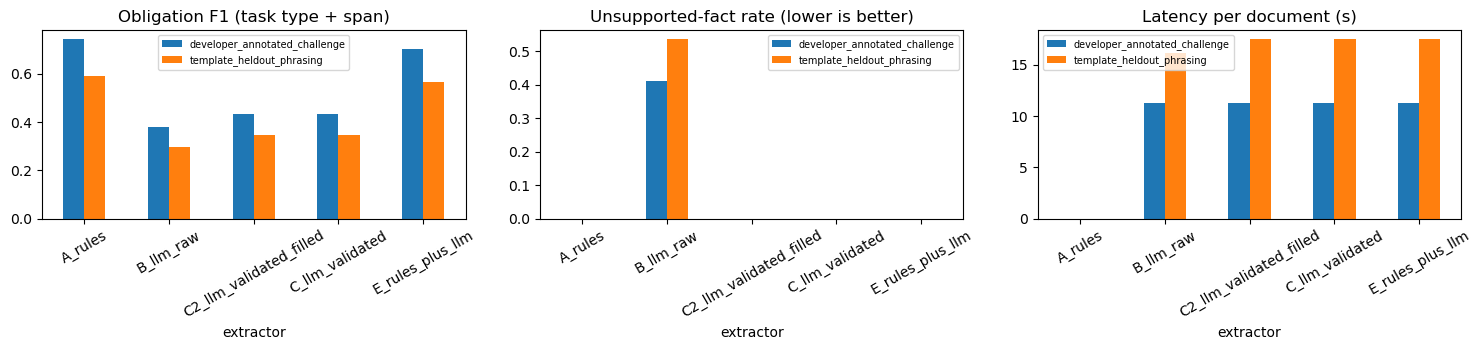

In [13]:
t = time.time()
E1 = run_exp1(lab, "primary", include=["A_rules", "B_llm_raw", "C_llm_validated", "C2_llm_validated_filled", "E_rules_plus_llm"])
cols = ["extractor", "corpus", "n_docs", "typed_precision", "typed_recall", "typed_f1", "typed_f1_lo", "typed_f1_hi", "det_f1", "deadline_acc", "spurious_deadlines", "role_acc", "cond_acc",
        "dep_f1_on_matched", "dep_matched_pairs", "unsupported_field_rate", "oblig_with_unsupported", "schema_valid", "latency_mean_s", "latency_p95_s"]
display(E1["table"][cols]); print("Experiment 1 took", round(time.time() - t), "s | LLM cache hits/misses:", E1["backend"].hits, E1["backend"].misses)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for k, (col, ttl) in enumerate((("typed_f1", "Obligation F1 (task type + span)"), ("unsupported_field_rate", "Unsupported-fact rate (lower is better)"), ("latency_mean_s", "Latency per document (s)"))):
    pv = E1["table"].pivot(index="extractor", columns="corpus", values=col); pv.plot(kind="bar", ax=ax[k]); ax[k].set_title(ttl); ax[k].tick_params(axis="x", rotation=30); ax[k].legend(fontsize=7)
plt.tight_layout(); viz.save(fig, cfg, "exp1_extraction"); plt.show()

In [14]:
cat = E1["per_category"]
display(cat[cat.corpus == "developer_annotated_challenge"].pivot(index="category", columns="extractor", values="f1").round(2).assign(support=cat[(cat.corpus == "developer_annotated_challenge") & (cat.extractor == "A_rules")].set_index("category").eval("tp + fn")))
display(cat[cat.corpus == "template_heldout_phrasing"].pivot(index="category", columns="extractor", values="f1").round(2).assign(support=cat[(cat.corpus == "template_heldout_phrasing") & (cat.extractor == "A_rules")].set_index("category").eval("tp + fn")))
# what validation actually removed from raw GenAI output
rej, rep_ = {}, {}
for (name, corpus), res in E1["results"].items():
    if name == "C_llm_validated":
        for r in res:
            for x in r.rejected: rej[x["reason"]] = rej.get(x["reason"], 0) + 1
            for x in r.repairs: rep_[f"{x.get('field')}:{x['action']}"] = rep_.get(f"{x.get('field')}:{x['action']}", 0) + 1
print("validation rejected (obligations):", rej); print("validation repaired (fields):", rep_)

extractor,A_rules,B_llm_raw,C2_llm_validated_filled,C_llm_validated,E_rules_plus_llm,support
category,,,,,,
appointment_referral,0.80,0.40,0.40,0.40,0.67,3
followup_review,0.50,0.00,0.00,0.00,0.50,4
imaging,1.00,0.40,0.40,0.40,1.00,3
laboratory_test,0.67,0.33,0.40,0.40,0.50,2
medication_action,0.80,0.75,0.86,0.86,0.80,3
other_action,0.00,0.40,0.50,0.50,0.00,1
patient_communication,1.00,0.40,0.40,0.40,1.00,3
procedure,0.00,0.00,0.00,0.00,0.00,1


extractor,A_rules,B_llm_raw,C2_llm_validated_filled,C_llm_validated,E_rules_plus_llm,support
category,,,,,,
appointment_referral,1.00,0.73,0.73,0.73,0.92,6
followup_review,0.44,0.27,0.29,0.29,0.53,12
imaging,0.00,0.00,0.00,0.00,0.00,1
laboratory_test,0.00,0.00,0.00,0.00,0.00,6
medication_action,0.92,0.35,0.43,0.43,0.80,7
other_action,0.00,0.00,0.00,0.00,0.00,0
patient_communication,0.00,0.25,0.29,0.29,0.00,4
procedure,0.00,0.00,0.00,0.00,0.00,0


validation rejected (obligations): {'evidence_span_not_in_source': 15, 'schema_validation': 3}
validation repaired (fields): {'responsible_role:dropped': 23, 'due_interval:dropped': 1}


In [15]:
big_ok = (ROOT / cfg["llm"]["models_dir"] / cfg["llm"]["large"].replace(".gguf", ".be.gguf")).exists() or (ROOT / cfg["llm"]["models_dir"] / "original_le" / cfg["llm"]["large"]).exists()
if big_ok:
    nl = lab.p["llm_large_docs"]
    t = time.time(); E1L = run_exp1(lab, "large", n_chal=nl["challenge"], n_tpl=nl["template"], include=["A_rules", "B_llm_raw", "C2_llm_validated_filled", "E_rules_plus_llm"])
    display(E1L["table"][["extractor", "model", "corpus", "n_docs", "typed_precision", "typed_recall", "typed_f1", "det_f1", "deadline_acc", "unsupported_field_rate", "schema_valid", "latency_mean_s", "latency_p95_s"]])
    print("larger-model comparison took", round(time.time() - t), "s on a SMALLER sample (n_docs above) because generation is ~5x slower")
else:
    print("larger local model not installed; skipping the upper-bound comparison")

,extractor,model,corpus,n_docs,typed_precision,typed_recall,typed_f1,det_f1,deadline_acc,unsupported_field_rate,schema_valid,latency_mean_s,latency_p95_s
0,A_rules,rules,developer_annotated_challenge,6,0.909,0.714,0.800,0.880,1.0,0.000,1.000,3.532e-03,0.013
1,B_llm_raw,granite-4.0-1b-Q4_0.be.gguf,developer_annotated_challenge,6,0.556,0.357,0.435,0.609,1.0,0.176,0.333,5.606e+01,89.319
2,C2_llm_validated_filled,granite-4.0-1b-Q4_0.be.gguf,developer_annotated_challenge,6,0.714,0.357,0.476,0.667,1.0,0.000,0.333,8.340e+01,196.172
3,E_rules_plus_llm,granite-4.0-1b-Q4_0.be.gguf,developer_annotated_challenge,6,0.909,0.714,0.800,0.880,1.0,0.000,0.333,8.340e+01,196.173
4,A_rules,rules,template_heldout_phrasing,6,0.900,0.500,0.643,0.714,1.0,0.000,1.000,6.404e-04,0.001
5,B_llm_raw,granite-4.0-1b-Q4_0.be.gguf,template_heldout_phrasing,6,0.625,0.556,0.588,0.765,1.0,0.040,0.500,6.098e+01,89.351
6,C2_llm_validated_filled,granite-4.0-1b-Q4_0.be.gguf,template_heldout_phrasing,6,0.667,0.556,0.606,0.788,1.0,0.000,0.500,6.098e+01,89.351
7,E_rules_plus_llm,granite-4.0-1b-Q4_0.be.gguf,template_heldout_phrasing,6,0.769,0.556,0.645,0.774,1.0,0.000,0.500,6.098e+01,89.352


larger-model comparison took 16 s on a SMALLER sample (n_docs above) because generation is ~5x slower


In [16]:
# Model selection from MEASURED quality (not assumed): average typed-F1 over both corpora, restricted to GenAI-based extractors, plus latency.
sel = E1["table"][E1["table"].extractor.isin(["B_llm_raw", "C2_llm_validated_filled", "E_rules_plus_llm"])].groupby("extractor")[["typed_f1", "unsupported_field_rate", "latency_mean_s"]].mean()
display(sel)
best_ext = sel.typed_f1.idxmax(); print("highest mean typed F1 among GenAI-based extractors (350M):", best_ext)
rules_f1 = E1["table"][E1["table"].extractor == "A_rules"].typed_f1.mean()
print(f"rule-based baseline mean typed F1 = {rules_f1:.3f}; best GenAI-based = {sel.typed_f1.max():.3f}")
print("DECISION: Granite-4.0-350M (Q8_0) alone is too weak to replace the rules (it under-extracts, omits deadlines and fabricates roles). It is kept only behind the validator and in the rules+GenAI ensemble (E), which adds the "
      "obligations the rules miss while every field stays evidence-grounded. The 1B model (if present above) is the measured upper-bound comparison.")
SELECTED_EXTRACTOR = "E_rules_plus_llm"

,typed_f1,unsupported_field_rate,latency_mean_s
extractor,,,
B_llm_raw,0.340,0.474,13.709
C2_llm_validated_filled,0.389,0.000,14.375
E_rules_plus_llm,0.635,0.000,14.376


highest mean typed F1 among GenAI-based extractors (350M): E_rules_plus_llm
rule-based baseline mean typed F1 = 0.668; best GenAI-based = 0.635
DECISION: Granite-4.0-350M (Q8_0) alone is too weak to replace the rules (it under-extracts, omits deadlines and fabricates roles). It is kept only behind the validator and in the rules+GenAI ensemble (E), which adds the obligations the rules miss while every field stays evidence-grounded. The 1B model (if present above) is the measured upper-bound comparison.


## 8. ML clinical action classification (Model A)

TF-IDF (word + character n-grams) with **logistic regression**, **linear SVM** and a **compact neural net** (TF-IDF -> SVD -> MLP). Hyper-parameters are chosen by random search on *train -> validation*
macro-F1 (budget in `config.yaml`); the test split is used once. Labels are **silver** (rule-proposed). `challenge_span_*` columns score the same classifier on **developer-annotated** obligation spans,
a different label source, to show how much the silver agreement overstates correctness.

Model A took 42 s


,model,params,val_macro_f1,val_micro_f1,test_macro_f1,test_micro_f1,test_micro_precision,test_micro_recall,challenge_span_accuracy,challenge_span_macro_f1,train_s,search_s
0,logreg,"{""kind"": ""logreg"", ""C"": 10.0, ""word_ngrams"": [1, 2], ""char"": true, ""class_weight"": null, ""seed"":...",0.621,0.864,0.595,0.831,0.888,0.782,0.231,0.324,1.850,3.587
1,svm,"{""kind"": ""svm"", ""C"": 10.0, ""word_ngrams"": [1, 2], ""char"": true, ""class_weight"": null, ""seed"": 20...",0.713,0.872,0.707,0.849,0.881,0.819,0.288,0.362,1.611,3.272
2,mlp,"{""kind"": ""mlp"", ""C"": 1.0, ""word_ngrams"": [1, 2], ""char"": true, ""class_weight"": null, ""seed"": 202...",0.624,0.855,0.609,0.820,0.868,0.776,0.250,0.364,18.802,31.109


best family: svm {'kind': 'svm', 'C': 10.0, 'word_ngrams': [1, 2], 'char': True, 'class_weight': None, 'seed': 20261017}


,class,precision,recall,f1,support
0,appointment_referral,0.922,0.680,0.783,122.0
1,laboratory_test,0.865,0.642,0.737,120.0
2,imaging,0.826,0.644,0.724,59.0
3,procedure,0.885,0.434,0.582,53.0
4,medication_action,0.841,0.652,0.735,469.0
5,patient_communication,0.813,0.578,0.676,128.0
6,followup_review,0.902,0.615,0.731,179.0
7,other_action,0.654,0.382,0.482,89.0
8,no_action,0.894,0.930,0.911,2283.0


{'test_macro_f1_without': 0.7067736470802068, 'test_macro_f1_with': 0.7056523763364008, 'challenge_span_acc_with': 0.4423076923076923, 'challenge_span_acc_without': 0.28846153846153844, 'n_synthetic': 622}
train/val/test labels are SILVER (rule-proposed); 'challenge_span_*' uses developer-annotated spans (not independently reviewed); 0 human-reviewed gold


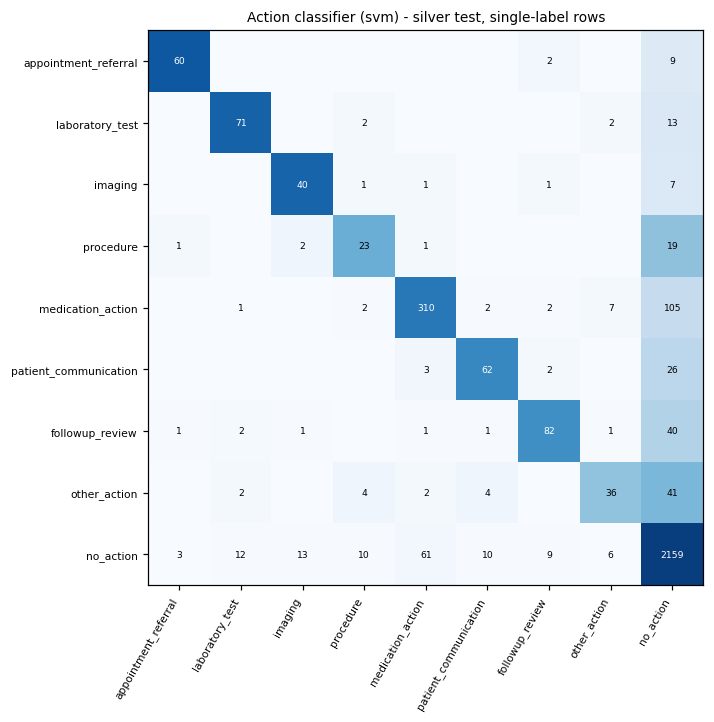

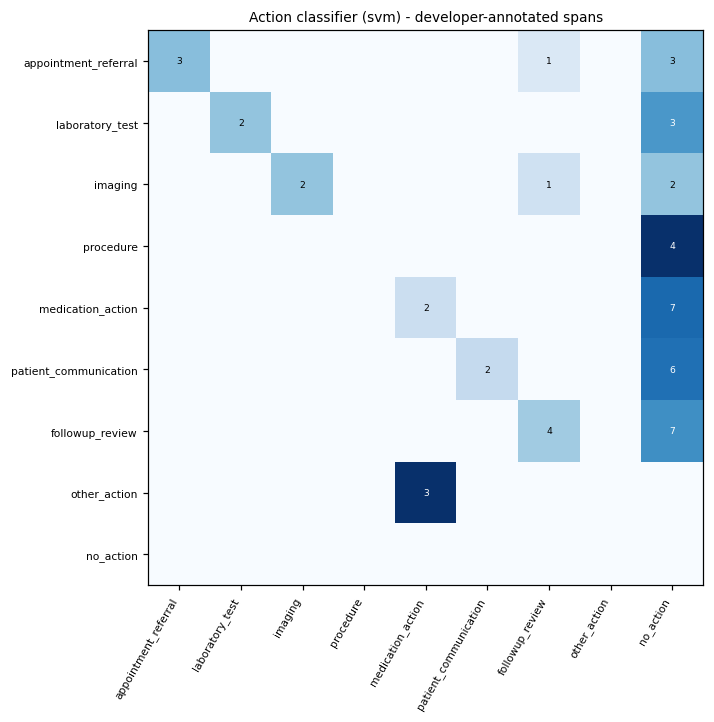

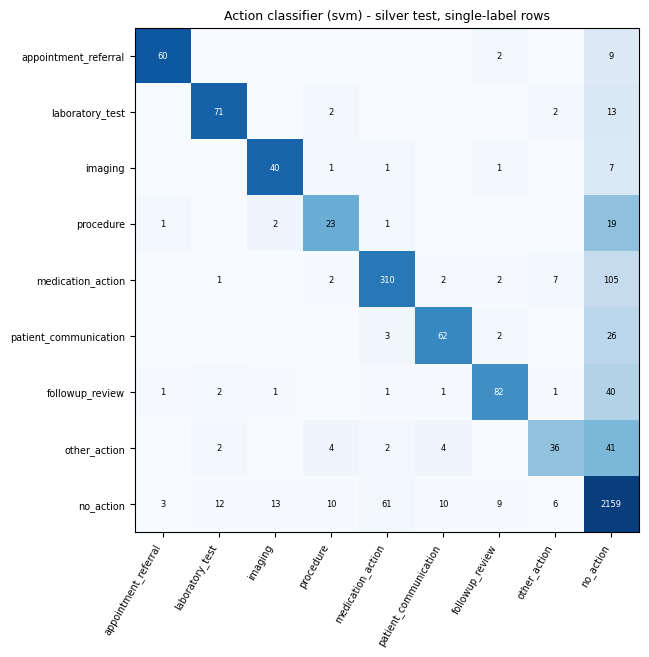

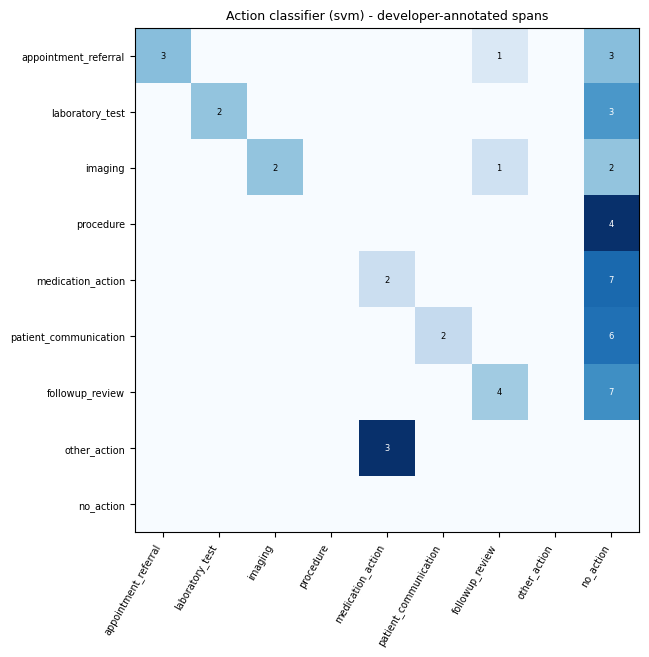

In [17]:
from src.experiments import model_a_action_classifier
t = time.time(); A_res = model_a_action_classifier(lab); print("Model A took", round(time.time() - t), "s")
display(A_res["comparison"].round(3)); print("best family:", A_res["best_kind"], A_res["best_params"])
display(A_res["per_class_test"].round(3)); print(A_res["synthetic_augmentation"]); print(A_res["label_provenance"])
from IPython.display import Image
for nm in ("model_a_confusion_silver", "model_a_confusion_spans"):
    display(Image(filename=str(ROOT / "figures" / f"{nm}.png")))

In [18]:
from src.evaluation import type_accuracy_on_detected
rows = []
chal = E1["corpora"]["developer_annotated_challenge"]
for (name, corpus), res in E1["results"].items():
    if corpus == "developer_annotated_challenge":
        rows.append({"system": f"extraction {name}", **type_accuracy_on_detected(chal, res)})
rows.append({"system": f"ML classifier ({A_res['best_kind']}) on the TRUE spans", "n_detected": int(sum(len(d['obligations']) for d in chal)),
             "type_accuracy": float(A_res["comparison"].set_index("model").loc[A_res["best_kind"], "challenge_span_accuracy"])})
display(pd.DataFrame(rows).round(3))
print("Fair-comparison note: both rows score the CATEGORY assigned to a span against developer annotations. The classifier is given the gold span; the extractors must also find the span "
      "(restricted here to spans they detected), so this favours neither strongly. Silver-test agreement is NOT correctness.")

,system,n_detected,type_accuracy
0,extraction A_rules,15,0.800
1,extraction B_llm_raw,14,0.571
2,extraction C_llm_validated,14,0.571
3,extraction C2_llm_validated_filled,14,0.571
4,extraction E_rules_plus_llm,16,0.750
5,ML classifier (svm) on the TRUE spans,20,0.288


Fair-comparison note: both rows score the CATEGORY assigned to a span against developer annotations. The classifier is given the gold span; the extractors must also find the span (restricted here to spans they detected), so this favours neither strongly. Silver-test agreement is NOT correctness.


## 9. Temporal evidence graph construction

Node types (Patient, Encounter, ClinicalNote, Obligation, Task, Result, Review, Acknowledgment, Notification, EvidenceEvent, ResponsibleRole), edge types (EXTRACTED_FROM, DEPENDS_ON, ASSIGNED_TO,
EVIDENCED_BY, COMPLETED_BY, REQUIRES_REVIEW, CONTRADICTS, BELONGS_TO). Workflow states come from deterministic rules R1-R7 that cite their evidence. The cells below *demonstrate* each required semantic on the scripted episode.

In [19]:
from src.event_processor import EventProcessor
from src.evidence_graph import TemporalEvidenceGraph, iso, to_epoch
from src.scenario_lab import demo_events, demo_obligations, T0
from src import visualization_demo as vd
H = 3600.0
PID = "demo:patient-001"
gp = EventProcessor(cfg, ":memory:", scorers={}, build_nx=True)
gp.run(demo_events("delayed_ack")); gp.finalize()
g = gp.graph
print("graph:", g.stats())
from collections import Counter
print("node types:", dict(Counter(d["ntype"] for _, d in g.G.nodes(data=True)))); print("edge types:", dict(Counter(d["etype"] for _, _, d in g.G.edges(data=True))))
for when, hours in (("after the lab test (+31h)", 31), ("after deadline of the review, tracker open (+122h)", 122), ("after the delayed acknowledgment is documented (+152h)", 152)):
    now = T0 + hours * H
    print("\n", when); display(pd.DataFrame([{"obligation": o.split(":")[-1], "step": g.obs[o].step_type, **{k: v for k, v in dict(state=g.derive_state(o, now, live=True).state.value, rule=g.derive_state(o, now, live=True).rule,
                                         evidence=g.derive_state(o, now, live=True).evidence_ids).items()}} for o in sorted(g.obs)]))

graph: {'obligations': 4, 'events_ingested': 13, 'duplicates_ignored': 0, 'nx_nodes': 17, 'nx_edges': 34, 'rejected_cycles': 0, 'orphan_events_waiting': 0, 'unresolved_dependencies': 0}
node types: {'Patient': 1, 'Obligation': 4, 'ResponsibleRole': 3, 'Notification': 2, 'Task': 3, 'Result': 1, 'Review': 1, 'EvidenceEvent': 1, 'Acknowledgment': 1}
edge types: {'BELONGS_TO': 13, 'ASSIGNED_TO': 4, 'EVIDENCED_BY': 9, 'COMPLETED_BY': 4, 'REQUIRES_REVIEW': 1, 'DEPENDS_ON': 3}

 after the lab test (+31h)


,obligation,step,state,rule,evidence
0,ob0,lab_collected,completed_with_evidence,R1_own_verified_completion_evidence,[demo:e02]
1,ob1,result_reviewed,pending,R4_before_deadline_no_completion,[]
2,ob2,patient_notified,pending,R4_before_deadline_no_completion,[]
3,ob3,followup_visit_completed,pending,R4_before_deadline_no_completion,[]



 after deadline of the review, tracker open (+122h)


,obligation,step,state,rule,evidence
0,ob0,lab_collected,completed_with_evidence,R1_own_verified_completion_evidence,[demo:e02]
1,ob1,result_reviewed,overdue_without_verified_completion,R5_deadline_passed_open_confirmed,[demo:e06]
2,ob2,patient_notified,pending,R4_before_deadline_no_completion,[]
3,ob3,followup_visit_completed,pending,R4_before_deadline_no_completion,[]



 after the delayed acknowledgment is documented (+152h)


,obligation,step,state,rule,evidence
0,ob0,lab_collected,completed_with_evidence,R1_own_verified_completion_evidence,[demo:e02]
1,ob1,result_reviewed,completed_with_evidence,R1_own_verified_completion_evidence,[demo:e05]
2,ob2,patient_notified,pending,R4_before_deadline_no_completion,[]
3,ob3,followup_visit_completed,pending,R4_before_deadline_no_completion,[]


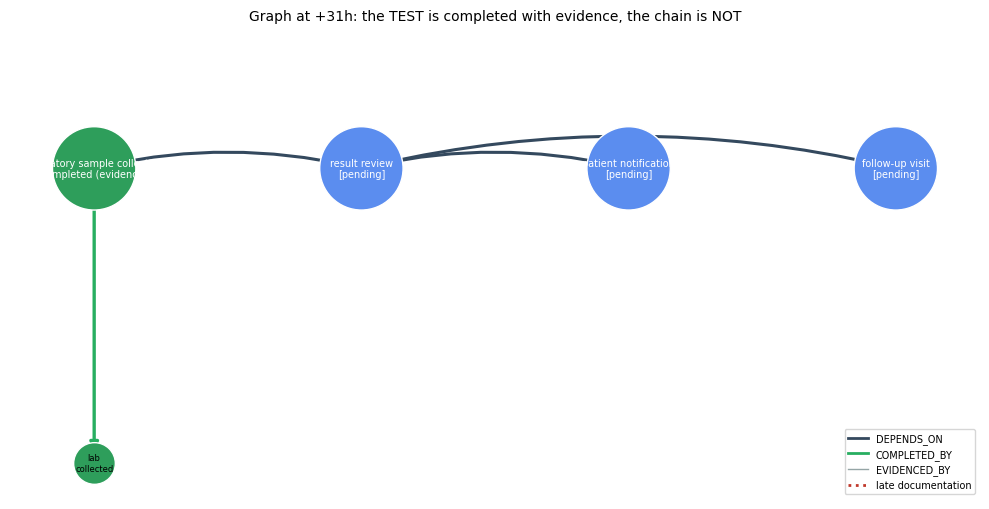

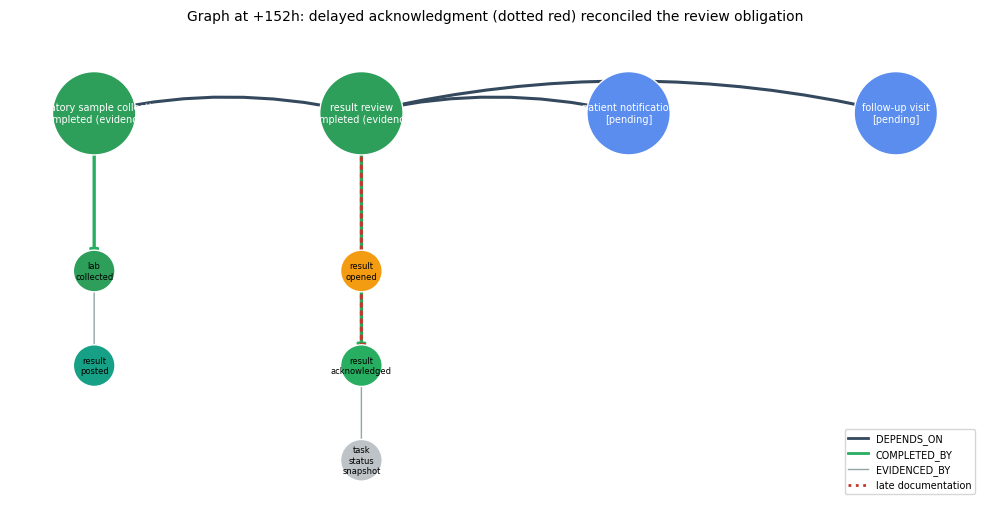

In [20]:
fig = vd.plot_evidence_graph(gp, PID, now=T0 + 31 * H, title="Graph at +31h: the TEST is completed with evidence, the chain is NOT"); viz.save(fig, cfg, "graph_t31"); plt.show()
fig = vd.plot_evidence_graph(gp, PID, now=T0 + 152 * H, title="Graph at +152h: delayed acknowledgment (dotted red) reconciled the review obligation"); viz.save(fig, cfg, "graph_t152"); plt.show()

In [21]:
# semantic checks, each executed live
from tests.conftest import mk_ev, mk_ob   # test helpers (synthetic records)
t0 = to_epoch("2024-03-04T09:00:00Z")
g1 = TemporalEvidenceGraph(12)
g1.ingest(mk_ob("o0", "lab_collected", t0, t0 + 48 * H, [], pos=0, n=3)); g1.ingest(mk_ob("o1", "result_reviewed", t0, t0 + 120 * H, ["o0"], pos=1, n=3)); g1.ingest(mk_ob("o2", "patient_notified", t0, t0 + 192 * H, ["o1"], pos=2, n=3))
g1.ingest(mk_ev("e1", "o0", "lab_collected", t0 + 10 * H))
checks = []
checks.append(("completed test does NOT complete the chain", [g1.derive_state(o, t0 + 20 * H).state.value for o in ("o0", "o1", "o2")]))
g1.ingest(mk_ev("e2", "o0", "result_posted", t0 + 14 * H)); g1.ingest(mk_ev("e3", "o1", "result_opened", t0 + 20 * H))
checks.append(("result available + opened is NOT an acknowledgment", (g1.derive_state("o1", t0 + 30 * H).state.value, g1.features("o1", t0 + 30 * H)["ack_state"])))
g1.ingest(mk_ev("e4", "o1", "result_acknowledged", t0 + 40 * H)); checks.append(("reviewed result does NOT notify the patient", (g1.derive_state("o1", t0 + 50 * H).state.value, g1.derive_state("o2", t0 + 50 * H).state.value)))
r = g1.ingest(mk_ev("e4", "o1", "result_acknowledged", t0 + 40 * H, t_ingest=t0 + 60 * H)); checks.append(("duplicate delivery ignored", (r.duplicate, g1.n_duplicates)))
g2 = TemporalEvidenceGraph(12); g2.ingest(mk_ob("a", "lab_collected", t0, t0 + H, ["b"])); rr = g2.ingest(mk_ob("b", "result_reviewed", t0, t0 + 2 * H, ["a"]))
checks.append(("cyclic dependency rejected", (rr.rejected, g2.rejected_cycles)))
g3 = TemporalEvidenceGraph(12); g3.ingest(mk_ob("x", "lab_collected", t0, t0 + 48 * H, [])); d = t0 + 48 * H
checks.append(("no evidence: grace -> unverified (not 'overdue')", [g3.derive_state("x", d + h * H).state.value for h in (1, 13)]))
g3.ingest(mk_ev("s", "x", "task_status_snapshot", d + H, details={"status": "open"})); checks.append(("tracker confirms open -> overdue", g3.derive_state("x", d + 2 * H).state.value))
g3.ingest(mk_ev("late", "x", "lab_collected", t0 + 40 * H, t_ingest=t0 + 90 * H)); checks.append(("late-documented completion reconciles (live view)", (g3.derive_state("x", d + 10 * H, live=True).state.value, g3.derive_state("x", d + 50 * H, live=True).state.value)))
g3.ingest(mk_ev("c", "x", "conflicting_record", t0 + 45 * H, ver="unverified")); checks.append(("contradictory evidence", g3.derive_state("x", d + 50 * H, live=True).state.value))
display(pd.DataFrame(checks, columns=["property", "observed"]))

,property,observed
0,completed test does NOT complete the chain,"[completed_with_evidence, pending, pending]"
1,result available + opened is NOT an acknowledgment,"(pending, viewed_unacknowledged)"
2,reviewed result does NOT notify the patient,"(completed_with_evidence, pending)"
3,duplicate delivery ignored,"(True, 1)"
4,cyclic dependency rejected,"(cycle:a->b, [(a, b)])"
5,no evidence: grace -> unverified (not 'overdue'),"[censored_not_yet_assessable, unverified_insufficient_evidence]"
6,tracker confirms open -> overdue,overdue_without_verified_completion
7,late-documented completion reconciles (live view),"(overdue_without_verified_completion, completed_with_evidence)"
8,contradictory evidence,contradictory_evidence


## 10. Follow-up risk prediction (Model B) - Experiment 2

Target: probability that an obligation **remains unresolved at its deadline**, from features available at the assessment time only (feature code = the evidence graph; events after the cutoff are invisible).
Training uses **dense snapshots** at 8 points across each obligation's window (the dataset pipeline's single 20-80 % assessment point is also reported as `orig_protocol_*`), only for obligations still open at the snapshot.
**Unverified and censored obligations are never treated as failures.** Families: logistic regression, HistGradientBoosting, random forest, XGBoost; feature sets: *task-only*, *B independent tasks* (no dependency/evidence-graph features), *C graph-enhanced*.
All labels are **simulated** follow-up outcomes.

Model B took 35 s


,model,features,val_pr_auc,test_pr_auc,test_pr_auc_ci_lo,test_pr_auc_ci_hi,test_roc_auc,test_brier,test_ece,test_brier_uncalibrated,test_ece_uncalibrated,orig_protocol_test_pr_auc
0,logreg/task_only,task_only,0.789,0.780,0.717,0.843,0.712,0.210,0.049,0.222,0.106,0.654
1,hgb/task_only,task_only,0.761,0.736,0.689,0.803,0.674,0.225,0.057,0.257,0.173,0.609
2,rf/task_only,task_only,0.819,0.792,0.739,0.853,0.736,0.200,0.021,0.200,0.042,0.647
3,xgboost/task_only,task_only,0.812,0.797,0.745,0.859,0.734,0.201,0.028,0.202,0.049,0.643
4,logreg/B_independent,B_independent,0.803,0.793,0.743,0.846,0.726,0.209,0.062,0.221,0.110,0.672
5,hgb/B_independent,B_independent,0.790,0.776,0.727,0.829,0.702,0.212,0.049,0.245,0.174,0.652
6,rf/B_independent,B_independent,0.833,0.818,0.767,0.878,0.755,0.196,0.033,0.197,0.044,0.683
7,xgboost/B_independent,B_independent,0.837,0.820,0.772,0.878,0.749,0.196,0.021,0.200,0.057,0.677
8,logreg/C_graph,C_graph,0.849,0.800,0.754,0.859,0.720,0.227,0.116,0.239,0.159,0.675
9,hgb/C_graph,C_graph,0.832,0.817,0.765,0.872,0.752,0.201,0.060,0.218,0.131,0.723


,model,n,prevalence,pr_auc,roc_auc,brier,ece,precision@0.5,recall@0.5,f1@0.5
0,majority(train prior),2103,0.586,0.586,0.500,0.247,0.066,0.586,1.000,0.739
1,deadline_only_logreg,2103,0.586,0.827,0.745,0.200,0.056,0.713,0.747,0.730


best per feature set: {'task_only': {'model': 'rf/task_only', 'val_pr_auc': 0.8194199109560125}, 'B_independent': {'model': 'xgboost/B_independent', 'val_pr_auc': 0.837060799600809}, 'C_graph': {'model': 'xgboost/C_graph', 'val_pr_auc': 0.866154322055589}}
paired patient-bootstrap differences in PR-AUC: {'C_minus_B_pr_auc': {'diff': 0.01029648899046276, 'lo': -0.0034313208289009464, 'hi': 0.02590126451064088, 'p_diff_le_0': 0.08, 'n_boot': 100}, 'C_minus_task_only_pr_auc': {'diff': 0.038400579252702904, 'lo': 0.019074095322651616, 'hi': 0.06006453460190801, 'p_diff_le_0': 0.0, 'n_boot': 100}}


,threshold,alerts,precision,recall
0,0.3,1862,0.613,0.927
1,0.5,1287,0.732,0.765
2,0.7,797,0.853,0.552
3,0.9,372,0.954,0.288


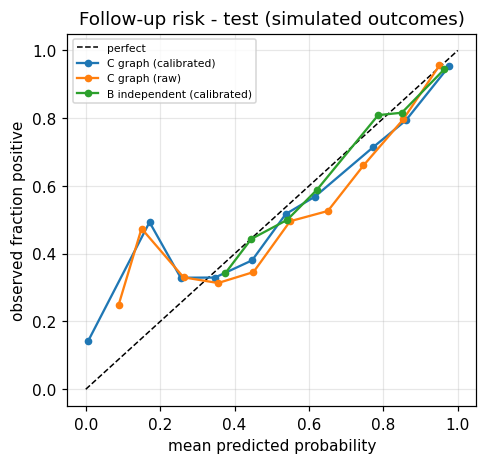

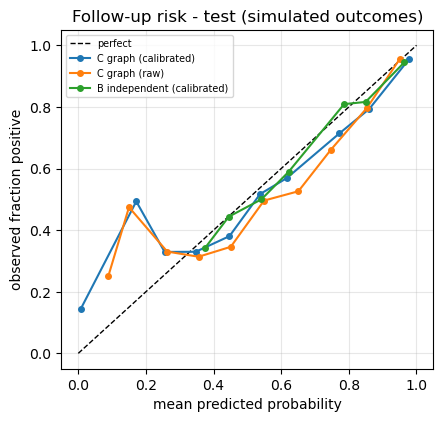

In [22]:
from src.experiments import model_b_followup_risk
t = time.time(); B_res = model_b_followup_risk(lab); print("Model B took", round(time.time() - t), "s")
cols = ["model", "features", "val_pr_auc", "test_pr_auc", "test_pr_auc_ci_lo", "test_pr_auc_ci_hi", "test_roc_auc", "test_brier", "test_ece", "test_brier_uncalibrated", "test_ece_uncalibrated", "orig_protocol_test_pr_auc"]
display(B_res["comparison"][cols].round(3)); display(B_res["baselines"].round(3))
print("best per feature set:", B_res["summary"]["best_per_featureset"]); print("paired patient-bootstrap differences in PR-AUC:", B_res["summary"]["paired_bootstrap"])
display(B_res["thresholds"].round(3)); display(Image(filename=str(ROOT / "figures" / "model_b_calibration.png")))

,feature_group,n_features,pr_auc_drop_mean,pr_auc_drop_std,base_pr_auc
0,task,11,1.880e-01,1.300e-03,0.83
3,graph_dependency,8,4.150e-02,1.200e-03,0.83
1,own_events,7,8.000e-03,1.300e-03,0.83
5,evidence,6,1.200e-03,5.000e-04,0.83
2,workload_history,8,-8.000e-04,7.000e-04,0.83
4,graph_temporal,9,-1.800e-03,3.100e-03,0.83


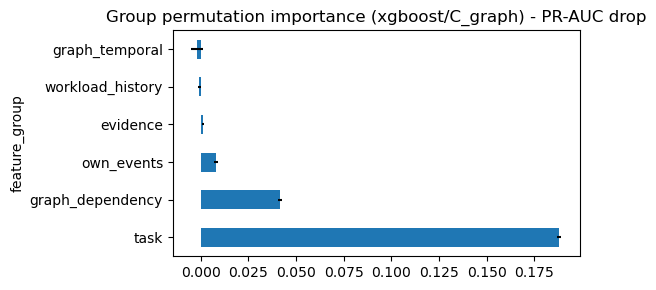

In [23]:
from src.risk_predictor import group_permutation_importance, binary
from src.ontology import FEATURE_GROUPS
te, yte = binary(lab.dense()["test"])
mC = B_res["best"]["C_graph"][0]
gi = group_permutation_importance(mC, te, yte, FEATURE_GROUPS, repeats=5 if MODE == "fast" else 10, seed=lab.seed)
display(gi.round(4))
ax = gi.set_index("feature_group").pr_auc_drop_mean.plot(kind="barh", xerr=gi.set_index("feature_group").pr_auc_drop_std, figsize=(6, 3)); ax.set_title(f"Group permutation importance ({mC.name}) - PR-AUC drop"); plt.tight_layout(); viz.save(plt.gcf(), cfg, "model_b_group_importance"); plt.show()

### Secondary model C: appointment no-show on **real** data

The only real (non-simulated) outcome in the project is appointment attendance (public Kaggle no-show data, de-identified). It is a proof of concept that the same calibrated-model recipe works on real scheduling data;
the label is **attendance, not follow-up completion**, and the model must never be used to deny or deprioritise care. A scheduling-only feature set is compared with one that adds demographics (which can encode bias).

Model C took 225 s | n: {'train': 31101, 'validation': 6506, 'test': 6727} | test prevalence 0.201


,model,features,val_pr_auc,test_pr_auc,pr_auc_ci_lo,pr_auc_ci_hi,test_roc_auc,test_brier,test_ece,prevalence,precision@top20%,recall@top20%,fit_s
0,logreg/scheduling_only,scheduling_only,0.320,0.304,0.289,0.321,0.704,0.146,0.014,0.201,0.315,0.605,35.936
1,hgb/scheduling_only,scheduling_only,0.336,0.334,0.312,0.357,0.722,0.144,0.007,0.201,0.337,0.497,40.563
2,xgboost/scheduling_only,scheduling_only,0.335,0.336,0.316,0.357,0.724,0.144,0.006,0.201,0.343,0.460,36.757
3,logreg/with_demographics,with_demographics,0.345,0.334,0.316,0.359,0.725,0.145,0.005,0.201,0.357,0.417,35.807
4,hgb/with_demographics,with_demographics,0.372,0.354,0.331,0.379,0.736,0.144,0.016,0.201,0.365,0.476,39.199
5,xgboost/with_demographics,with_demographics,0.370,0.360,0.337,0.384,0.738,0.143,0.006,0.201,0.347,0.577,36.543


selected on validation PR-AUC: hgb/with_demographics


,group,level,n,prevalence,mean_pred,pr_auc,flagged_share_top20
0,gender,F,4416,0.204,0.207,0.348,0.264
1,gender,M,2311,0.195,0.193,0.369,0.258
2,age_band,0-17,1684,0.213,0.204,0.369,0.291
3,age_band,18-34,1485,0.232,0.232,0.401,0.432
4,age_band,65+,774,0.152,0.175,0.269,0.054
5,age_band,35-49,1360,0.215,0.211,0.352,0.296
6,age_band,50-64,1424,0.168,0.177,0.274,0.133
7,scholarship,0,6091,0.197,0.199,0.349,0.247
8,scholarship,1,636,0.244,0.231,0.398,0.407


Brazilian public-hospital appointments (2016); attendance label only; demographic/geographic features can encode bias - the scheduling-only feature set is the recommended default; not for denying or deprioritising care


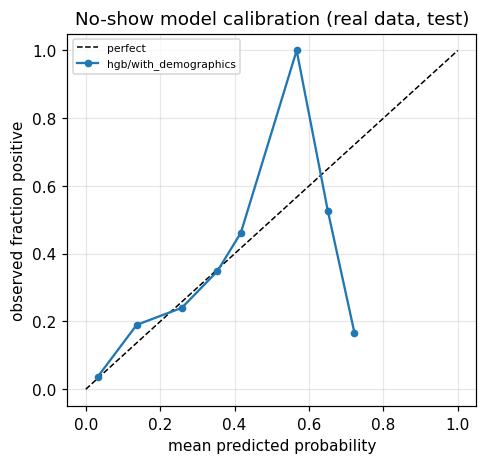

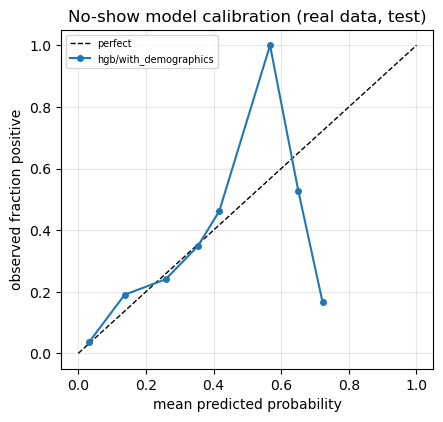

In [24]:
from src.experiments import model_c_noshow
t = time.time(); C_res = model_c_noshow(lab); print("Model C took", round(time.time() - t), "s | n:", C_res["n"], "| test prevalence %.3f" % C_res["prevalence_test"])
display(C_res["comparison"].round(3)); print("selected on validation PR-AUC:", C_res["selected"]); display(C_res["subgroups"].round(3)); print(C_res["caveats"])
display(Image(filename=str(ROOT / "figures" / "model_c_calibration.png")))

## 11. Hybrid GenAI + ML integration

The integration layer (`src/pipeline.py`) wires the pieces: the extractor *proposes* validated obligation records; the supervised classifier cross-checks the task type (strategy **D**); the evidence graph
turns records plus streaming events into deterministic states; the calibrated model forecasts risk. **The LLM never sets a workflow state.**

In [25]:
from src.exp_replay import load_scorers, replay, split_patients
t = time.time(); scorers = load_scorers(lab, ablations=True); print("scorers:", list(scorers), "| trained/loaded in", round(time.time() - t), "s")
E1D = run_exp1(lab, "primary", include=["A_rules", "C2_llm_validated_filled", "D_hybrid_llm_ml", "E_rules_plus_llm"])
display(E1D["table"][["extractor", "corpus", "typed_precision", "typed_recall", "typed_f1", "det_f1", "deadline_acc", "unsupported_field_rate", "latency_mean_s"]].round(3))
ov = sum(1 for (n, c), res in E1D["results"].items() if n == "D_hybrid_llm_ml" for r in res for x in r.repairs if x.get("action") == "overridden_by_classifier")
print("task_type overrides made by the ML classifier in strategy D:", ov)

scorers: ['A_deadline_only', 'A_reminder_24h', 'B_independent_ml', 'C_graph_ml', 'C_no_graph_dependency', 'C_no_temporal', 'C_no_evidence', 'C_no_graph_temporal'] | trained/loaded in 0 s


,extractor,corpus,typed_precision,typed_recall,typed_f1,det_f1,deadline_acc,unsupported_field_rate,latency_mean_s
0,A_rules,developer_annotated_challenge,0.867,0.650,0.743,0.857,1.0,0.0,0.001
1,C2_llm_validated_filled,developer_annotated_challenge,0.471,0.400,0.432,0.757,1.0,0.0,11.250
2,E_rules_plus_llm,developer_annotated_challenge,0.765,0.650,0.703,0.865,1.0,0.0,11.250
3,D_hybrid_llm_ml,developer_annotated_challenge,0.588,0.500,0.541,0.757,1.0,0.0,11.250
4,A_rules,template_heldout_phrasing,0.889,0.444,0.593,0.667,1.0,0.0,0.001
5,C2_llm_validated_filled,template_heldout_phrasing,0.455,0.278,0.345,0.586,1.0,0.0,17.501
6,E_rules_plus_llm,template_heldout_phrasing,0.708,0.472,0.567,0.767,1.0,0.0,17.501
7,D_hybrid_llm_ml,template_heldout_phrasing,0.500,0.306,0.379,0.586,1.0,0.0,17.501


task_type overrides made by the ML classifier in strategy D: 5


In [26]:
from src.pipeline import HybridPipeline, script_events_for_created
pipe = HybridPipeline(cfg, make_extractors(cached_backend(lab, "primary"), E1D["classifier"])[SELECTED_EXTRACTOR], {"B_independent_ml": scorers["B_independent_ml"], "C_graph_ml": scorers["C_graph_ml"]}, build_nx=True)
res, created = pipe.ingest_note(DEMO_TEXT, "demo-note-1", "demo:patient-001")
print("extractor:", res.extractor, "| obligations:", len(res.obligations), "| latency %.1fs" % res.latency_s); print("DEMO TEXT:", DEMO_TEXT)
display(pd.DataFrame([{"obligation": o.obligation_id.split(":")[-1], "task_type": o.task_type, "due": o.due_interval, "role": o.responsible_role, "depends_on": [d.split(":")[-1] for d in o.dependencies],
                       "conditional": o.conditional_requirements, "span": o.evidence_span.text, "missing_information": o.missing_information, "confidence": round(o.confidence, 2)} for o in res.obligations]))
print("monitored obligations after extraction (all pending until evidence arrives):"); display(pipe.report()[["obligation", "step", "deadline", "depends_on", "state", "risk"]])

extractor: E_rules_plus_llm | obligations: 4 | latency 18.5s
DEMO TEXT: Patient discharged after pneumonia admission. Repeat the CBC within 48 hours. The treating physician must review the result. Contact the patient if the result is abnormal. Arrange a follow-up appointment in 2 weeks.


,obligation,task_type,due,role,depends_on,conditional,span,missing_information,confidence
0,ob0,laboratory_test,PT48H,None,[],None,Repeat the CBC within 48 hours,[responsible_role],0.80
1,ob1,followup_review,None,ordering_clinician,[ob0],None,The treating physician must review the result,[deadline],0.75
2,ob2,patient_communication,None,None,[ob1],if the result is abnormal,Contact the patient if the result is abnormal,"[deadline, responsible_role]",0.65
3,ob3,appointment_referral,P2W,None,[ob1],None,Arrange a follow-up appointment in 2 weeks,[responsible_role],0.80


monitored obligations after extraction (all pending until evidence arrives):


,obligation,step,deadline,depends_on,state,risk
0,demo-note-1:x0,lab_collected,2024-03-06T09:00:00Z,[],pending,0.537
1,demo-note-1:x1,result_reviewed,2024-03-09T09:00:00Z,[demo-note-1:x0],pending,0.537
2,demo-note-1:x2,patient_notified,2024-03-12T09:00:00Z,[demo-note-1:x1],pending,0.614
3,demo-note-1:x3,appointment_attended,2024-03-18T09:00:00Z,[demo-note-1:x1],pending,0.537


In [27]:
script = script_events_for_created(created, "delayed_ack")
for k in (3, 6, len(script)):
    pipe2 = HybridPipeline(cfg, make_extractors(cached_backend(lab, "primary"), E1D["classifier"])[SELECTED_EXTRACTOR], {"B_independent_ml": scorers["B_independent_ml"], "C_graph_ml": scorers["C_graph_ml"]})
    pipe2.ingest_note(DEMO_TEXT, "demo-note-1", "demo:patient-001"); pipe2.feed(script[:k]);
    pipe2.proc._advance(to_epoch(script[k - 1]["ingest_time_utc"]) + 1); pipe2.proc.flush()
    print(f"\nafter {k}/{len(script)} streamed events:"); display(pipe2.report()[["step", "state", "late", "risk", "rule"]])
print("alerts raised:", [(a.rule, a.status) for a in pipe2.proc.alert_log][:8])


after 3/8 streamed events:


,step,state,late,risk,rule
0,lab_collected,completed_with_evidence,False,0.772,R1_own_verified_completion_evidence
1,result_reviewed,pending,False,0.380,R4_before_deadline_no_completion
2,patient_notified,pending,False,0.614,R4_before_deadline_no_completion
3,appointment_attended,pending,False,0.537,R4_before_deadline_no_completion



after 6/8 streamed events:


,step,state,late,risk,rule
0,lab_collected,completed_with_evidence,False,0.772,R1_own_verified_completion_evidence
1,result_reviewed,completed_with_evidence,False,0.961,R1_own_verified_completion_evidence
2,patient_notified,pending,False,0.772,R4_before_deadline_no_completion
3,appointment_attended,pending,False,0.772,R4_before_deadline_no_completion



after 8/8 streamed events:


,step,state,late,risk,rule
0,lab_collected,completed_with_evidence,False,0.772,R1_own_verified_completion_evidence
1,result_reviewed,completed_with_evidence,False,0.961,R1_own_verified_completion_evidence
2,patient_notified,completed_with_evidence,False,0.772,R1_own_verified_completion_evidence
3,appointment_attended,completed_with_evidence,False,0.852,R1_own_verified_completion_evidence


alerts raised: [('HIGH_RISK', 'resolved'), ('RESULT_NOT_ACKNOWLEDGED', 'resolved'), ('HIGH_RISK', 'resolved'), ('BLOCKED_BY_UPSTREAM', 'resolved'), ('HIGH_RISK', 'resolved'), ('DEADLINE_MISSED_CONFIRMED', 'resolved')]


In [28]:
from src.alert_engine import verbalize_alert
a = next((x for x in pipe2.proc.alert_log), None)
if a is not None:
    print("DETERMINISTIC, evidence-grounded explanation (record of truth):\n", a.explanation)
    v = verbalize_alert(cached_backend(lab, "primary").backend, a)
    print("\nOptional GenAI paraphrase | grounded =", v["grounded"], "| foreign tokens:", v["foreign_tokens"], "| %.1fs" % v["latency_s"]); print(v["llm_text"]); print("\nDISPLAYED:", v["text"][:600])

DETERMINISTIC, evidence-grounded explanation (record of truth):
 Predicted probability of being unresolved at the deadline is 77% (calibrated model forecast, not an observed failure). Task: laboratory sample collection (obligation demo-note-1:x0, due 2024-03-06T09:00:00Z). State: pending. Evidence used: none documented. Missing: completion evidence. Responsible role: patient. Suggested verification (for qualified human review): Check with the patient/laboratory whether the specimen was collected; contact the patient if not. Uncertainty: model forecast (calibrated probability 0.77); the forecast can be wrong.



Optional GenAI paraphrase | grounded = False | foreign tokens: [] | 8.3s
The probability of being unresolved at the deadline is 77%. The task is pending, and evidence used is none documented. The responsible role is the patient. Suggested verification involves checking if the specimen was collected and contacting the patient if not. Uncertainty exists in the model forecast (calibrated probability 0.77).

DISPLAYED: Predicted probability of being unresolved at the deadline is 77% (calibrated model forecast, not an observed failure). Task: laboratory sample collection (obligation demo-note-1:x0, due 2024-03-06T09:00:00Z). State: pending. Evidence used: none documented. Missing: completion evidence. Responsible role: patient. Suggested verification (for qualified human review): Check with the patient/laboratory whether the specimen was collected; contact the patient if not. Uncertainty: model forecast (calibrated probability 0.77); the forecast can be wrong.


## 12. Real-time event processing

The replay engine streams the processed event stream (held-out **test** patients) through `EventProcessor`: per delivery it (1) validates schema/provenance, (2) resolves patient/obligation, (3) updates the temporal evidence graph,
(4) recomputes affected states, (5) builds current-time features, (6) scores risk with the live models, (7) applies deterministic alert rules, (8) builds an evidence-grounded explanation, (9) appends to the audit log.
State is persisted in **SQLite (WAL)**; processing is **idempotent**; event time and ingestion time are kept separately; the stream contains late, duplicated and out-of-order deliveries.

In [29]:
from src.exp_replay import replay, split_patients, truth_frame
from src.event_processor import EventProcessor, deadline_only_score
from src.data_loader import iter_stream
db_path = ROOT / cfg["paths"]["db"]
for suf in ("", "-wal", "-shm"):
    (Path(str(db_path) + suf)).unlink(missing_ok=True)
pt = split_patients(lab, "test")
events_test = list(iter_stream(cfg, patients=pt))
t = time.time()
proc = replay(lab, pt, scorers, events=events_test, db=str(db_path), rescore_batch=1, track_latency=True, build_nx=True)
wall = time.time() - t
lat = np.array(proc.latencies) * 1000
print(f"replayed {len(events_test)} deliveries for {len(pt)} test patients in {wall:.1f}s -> {len(events_test)/wall:.0f} deliveries/s with per-event streaming inference (3 risk scorers) and SQLite persistence")
print("per-delivery latency ms p50/p95/p99:", np.percentile(lat, [50, 95, 99]).round(2)); print("processor counters:", dict(proc.stats))
print("graph:", proc.graph.stats()); print("final workflow states:", proc.state_counts()); print("database integrity:", proc.integrity_check())

replayed 1788 deliveries for 60 test patients in 27.5s -> 65 deliveries/s with per-event streaming inference (3 risk scorers) and SQLite persistence
per-delivery latency ms p50/p95/p99: [15.46 48.01 76.53]
processor counters: {'deliveries': 1788, 'duplicates': 45, 'transitions': 1270, 'timer_fired': 2798, 'alert:HIGH_RISK': 289, 'alert:COMPLETION_UNVERIFIED': 64, 'alerts_resolved': 510, 'late_events': 61, 'alert:DEADLINE_MISSED_CONFIRMED': 75, 'alert:CONFLICTING_EVIDENCE': 11, 'alert:BLOCKED_BY_UPSTREAM': 92, 'alert:RESULT_NOT_ACKNOWLEDGED': 89}
graph: {'obligations': 432, 'events_ingested': 1743, 'duplicates_ignored': 45, 'nx_nodes': 1353, 'nx_edges': 3394, 'rejected_cycles': 0, 'orphan_events_waiting': 0, 'unresolved_dependencies': 0}
final workflow states: {'completed_with_evidence': 322, 'overdue_without_verified_completion': 75, 'contradictory_evidence': 11, 'unverified_insufficient_evidence': 24}
database integrity: {'sqlite_integrity': 'ok', 'events': 1743, 'event_ids_unique': T

In [30]:
al = proc.alerts_df(); display(al.rule.value_counts().rename("alerts").to_frame().T); display(al.head(5))
display(proc.audit_df().head(8)[["oid", "t_ingest", "old_state", "new_state", "rule", "trigger_event_id"]])
print("example grounded alert:\n", next(a for a in proc.alert_log if a.rule == "RESULT_NOT_ACKNOWLEDGED").explanation)

rule,HIGH_RISK,BLOCKED_BY_UPSTREAM,RESULT_NOT_ACKNOWLEDGED,DEADLINE_MISSED_CONFIRMED,COMPLETION_UNVERIFIED,CONFLICTING_EVIDENCE
alerts,289,92,89,75,64,11


,alert_id,oid,rule,severity,t_ingest,status,resolved_at,resolution,risk,priority
0,alert-0000001,sim:ob:seed008928:1,HIGH_RISK,high,1985-06-16T01:49:06Z,resolved,1985-06-17T13:49:07Z,superseded by COMPLETION_UNVERIFIED,0.961,0.752
1,alert-0000002,sim:ob:seed008928:1,COMPLETION_UNVERIFIED,medium,1985-06-17T13:49:07Z,resolved,1985-06-20T05:57:56Z,completion evidence received (late),NaN,NaN
2,alert-0000003,sim:ob:seed008836:1,HIGH_RISK,medium,1997-11-08T01:49:50Z,resolved,1997-11-09T01:49:51Z,superseded by DEADLINE_MISSED_CONFIRMED,0.880,0.657
3,alert-0000004,sim:ob:seed008836:1,DEADLINE_MISSED_CONFIRMED,high,1997-11-09T01:49:51Z,open,None,None,NaN,NaN
4,alert-0000005,sim:ob:seed008787:0,CONFLICTING_EVIDENCE,medium,2007-07-06T10:05:01Z,open,None,None,NaN,NaN


,oid,t_ingest,old_state,new_state,rule,trigger_event_id
0,sim:ob:seed008928:0,1985-05-18T01:49:18Z,None,pending,R4_before_deadline_no_completion,sim:ob:seed008928:0:created
1,sim:ob:seed008928:1,1985-05-18T01:49:22Z,None,pending,R4_before_deadline_no_completion,sim:ob:seed008928:1:created
2,sim:ob:seed008928:0,1985-05-18T21:14:02Z,pending,completed_with_evidence,R1_own_verified_completion_evidence,sim:ev:seed008928:0:1
3,sim:ob:seed008928:1,1985-06-17T01:49:07Z,pending,censored_not_yet_assessable,R6_deadline_passed_awaiting_late_evidence,timer:deadline
4,sim:ob:seed008928:1,1985-06-17T13:49:07Z,censored_not_yet_assessable,unverified_insufficient_evidence,R7_deadline_passed_no_evidence_either_way,timer:grace_end
5,sim:ob:seed008928:1,1985-06-20T05:57:56Z,unverified_insufficient_evidence,completed_with_evidence,R1_own_verified_completion_evidence,sim:ev:seed008928:1:2
6,sim:ob:seed008786:0,1996-11-05T11:58:18Z,None,pending,R4_before_deadline_no_completion,sim:ob:seed008786:0:created
7,sim:ob:seed008786:1,1996-11-05T11:58:20Z,None,pending,R4_before_deadline_no_completion,sim:ob:seed008786:1:created


example grounded alert:
 Result opened but not acknowledged 36 h ago. No documented acknowledgment found. This review obligation requires verification before the dependent task can be considered completed. Task: result review (obligation sim:ob:seed007629:1, due 2016-12-16T11:58:03Z). State: pending. Evidence used: none documented. Missing: acknowledgment of the result. Responsible role: ordering clinician. Suggested verification (for qualified human review): Ask the ordering clinician to confirm whether the result was reviewed and to document the acknowledgment. Uncertainty: acknowledgment may have occurred without documentation.


In [31]:
# idempotency: re-delivering events changes nothing
before = {o: (s[0], s[2]) for o, s in proc.states.items()}; n_tr = len(proc.transitions)
proc.run(events_test[:3000]); proc.finalize()
after = {o: (s[0], s[2]) for o, s in proc.states.items()}
print("re-delivered 3000 events: states changed =", sum(before[o] != after[o] for o in before), "| new transitions =", len(proc.transitions) - n_tr, "| duplicates ignored so far =", proc.graph.n_duplicates)
# crash recovery: rebuild from the persisted event log only
proc.commit()
t = time.time(); rec = EventProcessor.recover(cfg, db_path, scorers={}); 
same = np.mean([rec.states[o][0] == proc.states[o][0] for o in proc.states if o in rec.states])
print(f"recovered {rec.graph.stats()['obligations']} obligations / {rec.graph.stats()['events_ingested']} events from SQLite in {time.time()-t:.1f}s; stored states restored identically: {same:.3f}")
# reproducibility: a second replay of the same stream gives identical audit trails
p2 = replay(lab, pt, scorers, events=events_test, rescore_batch=1, build_nx=False)
sig = lambda p: [(t["oid"], t["new_state"], t["rule"]) for t in p.transitions]
print("replay reproducibility (identical transition sequence in a second, independent run):", sig(proc) == sig(p2), f"| {len(sig(p2))} transitions")

re-delivered 3000 events: states changed = 0 | new transitions = 0 | duplicates ignored so far = 1833
recovered 432 obligations / 1743 events from SQLite in 0.0s; stored states restored identically: 1.000


replay reproducibility (identical transition sequence in a second, independent run): True | 1270 transitions


## 13. Closed-loop evidence verification

In [32]:
from src.exp_replay import run_exp3, run_exp4, verification_metrics
t = time.time(); E3 = run_exp3(lab, scorers); print("Experiment 3 replay+evaluation took", round(time.time() - t), "s"); print(E3["n"])
se = E3["state_eval"]
display(pd.DataFrame({k: {"accuracy at t*=deadline+grace+1h": v["accuracy"], **{f"recall[{c}]": r for c, r in v["per_class_recall"].items()}} for k, v in se.items()}).T.round(3))
display(se["engine_evidence_aware"]["confusion"]); display(se["naive_absence_is_failure"]["confusion"])
print("t* is evaluated using only evidence INGESTED by t*; 'engine_final_after_reconciliation' = same engine after all late evidence arrived.")

Experiment 3 replay+evaluation took 40 s
{'val_obligations': 195, 'test_obligations': 319, 'test_overdue': 105, 'test_completed': 178, 'test_unverified_or_censored': 36, 'test_patients': 60}


,accuracy at t*=deadline+grace+1h,recall[completed],recall[overdue],recall[not_confirmed]
engine_evidence_aware,0.903,0.994,0.724,0.972
engine_final_after_reconciliation,0.997,1.000,1.000,0.972
naive_absence_is_failure,0.884,0.994,1.000,0.000


col_0,completed,not_confirmed,overdue
true_class,,,
completed,177,1,0
not_confirmed,0,35,1
overdue,0,29,76


col_0,completed,overdue
true_class,,
completed,177,1
not_confirmed,10,26
overdue,0,105


t* is evaluated using only evidence INGESTED by t*; 'engine_final_after_reconciliation' = same engine after all late evidence arrived.


In [33]:
VM = verification_metrics(lab, E3["processor_test"], truth_frame(lab, E3["processor_test"]), list(iter_stream(cfg, patients=split_patients(lab, "test"))))
display(pd.DataFrame({"value": VM}).astype(str))

,value
completion_evidence_recall,1.0
dependency_pairs_checked,173
dependency_verification_accuracy,0.9942196531791907
evidence_matching_accuracy,1.0
evidence_matching_precision,1.0
fraction_tasks_with_unresolved_evidence,0.08101851851851852
n_compared,432
out_of_order_final_state_agreement,1.0
out_of_order_noisy_stream,"{'late_events': 61, 'duplicates': 45}"


In [34]:
t = time.time(); E4 = run_exp4(lab, rate=0.3); print("Experiment 4 took", round(time.time() - t), "s")
display(E4["table"].round(3).T)
print("Reading: 'missing_completion' - the task was done but its evidence was deleted: the evidence-aware engine must NOT call it a confirmed failure (naive deadline logic does). 'delayed_evidence' - interim state wrongly "
      "overdue under the naive rule, reconciled by the engine. 'contradictory' - naive logic counts it completed. 'unacknowledged_results' - the engine alerts before the deadline. 'duplicates' - states unchanged.")

Experiment 4 took 2 s


,0,1,2,3,4
injection,missing_completion,delayed_evidence,contradictory,unacknowledged_results,duplicates
affected,53,53,53,23,340
engine_declared_confirmed_overdue,0.0,0.0,NaN,NaN,NaN
engine_flagged_unverified_or_not_assessable,1.0,0.377,NaN,NaN,NaN
naive_declared_overdue,1.0,0.377,NaN,NaN,NaN
engine_metric,"should NOT be 'confirmed overdue' (documentation missing, task actually done)",interim: not confirmed overdue; final: reconciled to completed,contradictory state,alerts before the deadline (reactive rules only fire after),idempotency (final states unchanged)
naive_metric,absence=failure,interim false overdue,treated as completed,flags only after the deadline,-
engine_final_completed_after_reconciliation,NaN,1.0,NaN,NaN,NaN
engine_flagged_contradictory,NaN,NaN,1.0,NaN,NaN
naive_declared_completed,NaN,NaN,1.0,NaN,NaN


Reading: 'missing_completion' - the task was done but its evidence was deleted: the evidence-aware engine must NOT call it a confirmed failure (naive deadline logic does). 'delayed_evidence' - interim state wrongly overdue under the naive rule, reconciled by the engine. 'contradictory' - naive logic counts it completed. 'unacknowledged_results' - the engine alerts before the deadline. 'duplicates' - states unchanged.


## 14. Baseline comparisons and ablations

**Experiment 3 (main).** Three systems on the *same* replayed stream of held-out patients: **A** deadline-only reminders, **B** independent tasks + ML, **C** dependency-aware evidence graph + ML.
Operating thresholds are chosen on *validation* patients for a target recall and applied unchanged to *test* patients. The key early-warning requirement is *minimum lead*: alerts must be raised at least 0/24/72 h before the deadline.

In [35]:
ew = E3["early_warning"]; sy = E3["summary"]
display(sy.round(3))
for lead in (24.0, 72.0):
    print(f"--- alerts required at least {lead:.0f} h before the deadline; thresholds from VALIDATION at recall target 0.7, applied to TEST")
    display(ew[(ew.min_lead_h == lead) & (ew["target_recall(val)"] == 0.7)][["system", "threshold(val)", "alerts", "recall", "precision", "false_alert_rate", "median_lead_h", "alerts_on_unverified_or_censored"]].round(3))
print("paired patient-bootstrap differences in max-score PR-AUC:", E3["paired"])

,system,pr_auc_max_score,pr_auc_lo,pr_auc_hi,pr_auc_at_T-24h,pr_auc_at_T-72h,roc_auc_max_score
0,A_deadline_only,0.981,0.951,0.999,0.739,0.501,0.993
1,A_reminder_24h,0.827,0.724,0.898,0.371,0.371,0.938
2,B_independent_ml,0.963,0.934,0.984,0.709,0.542,0.985
3,C_graph_ml,0.969,0.948,0.989,0.832,0.681,0.982
4,C_no_graph_dependency,0.961,0.939,0.981,0.719,0.606,0.978
5,C_no_temporal,0.547,0.418,0.656,0.620,0.541,0.637
6,C_no_evidence,0.971,0.951,0.990,0.841,0.691,0.984
7,C_no_graph_temporal,0.979,0.955,0.994,0.846,0.701,0.990


--- alerts required at least 24 h before the deadline; thresholds from VALIDATION at recall target 0.7, applied to TEST


,system,threshold(val),alerts,recall,precision,false_alert_rate,median_lead_h,alerts_on_unverified_or_censored
4,A_deadline_only,0.667,167,1.000,0.755,0.191,36.000,28
13,A_reminder_24h,1.000,155,1.000,0.827,0.124,24.000,28
22,B_independent_ml,0.846,120,0.800,0.832,0.096,24.000,19
31,C_graph_ml,0.852,108,0.743,0.867,0.067,72.000,18
40,C_no_graph_dependency,0.889,104,0.714,0.852,0.073,24.000,16
49,C_no_temporal,0.634,248,0.819,0.394,0.742,143.988,30
58,C_no_evidence,0.866,121,0.810,0.833,0.096,72.000,19
67,C_no_graph_temporal,0.846,107,0.752,0.888,0.056,72.000,18


--- alerts required at least 72 h before the deadline; thresholds from VALIDATION at recall target 0.7, applied to TEST


,system,threshold(val),alerts,recall,precision,false_alert_rate,median_lead_h,alerts_on_unverified_or_censored
7,A_deadline_only,0.500,122,0.629,0.611,0.236,78.000,14
16,A_reminder_24h,0.000,189,0.629,0.384,0.596,143.999,17
25,B_independent_ml,0.413,159,0.600,0.434,0.461,143.996,14
34,C_graph_ml,0.380,160,0.629,0.455,0.444,143.997,15
43,C_no_graph_dependency,0.381,186,0.629,0.388,0.584,143.999,16
52,C_no_temporal,0.476,184,0.610,0.381,0.584,143.999,16
61,C_no_evidence,0.310,173,0.629,0.418,0.517,143.998,15
70,C_no_graph_temporal,0.446,150,0.619,0.481,0.393,143.996,15


paired patient-bootstrap differences in max-score PR-AUC: {'C_minus_A': {'diff': -0.012444659780881717, 'lo': -0.033663479308881056, 'hi': 0.017073152114724675, 'p_diff_le_0': 0.8, 'n_boot': 100}, 'C_minus_B': {'diff': 0.005538057327209245, 'lo': -0.014985458004868526, 'hi': 0.027433434438922738, 'p_diff_le_0': 0.29, 'n_boot': 100}}


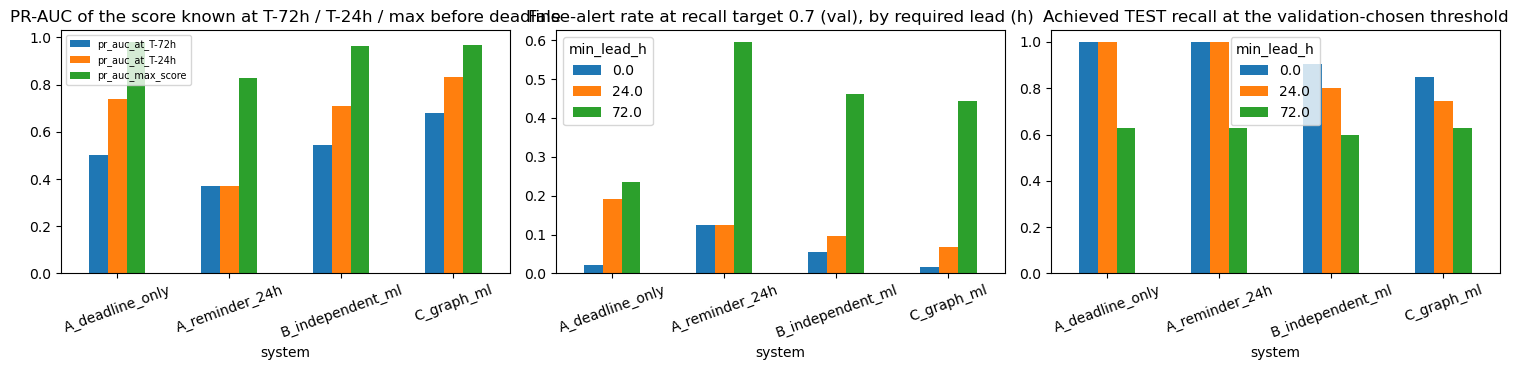

,rule,alerts,precision_vs_overdue,on_completed,on_unverified_or_censored,median_lead_h(before deadline)
0,BLOCKED_BY_UPSTREAM,81,0.79,14,13,72.00
1,COMPLETION_UNVERIFIED,64,0.97,1,32,-12.00
2,CONFLICTING_EVIDENCE,11,0.00,0,11,NaN
3,DEADLINE_MISSED_CONFIRMED,75,1.00,0,1,-1.01
4,HIGH_RISK,286,0.78,32,140,36.00
5,RESULT_NOT_ACKNOWLEDGED,89,0.51,36,15,36.00


Engine alerts (system C default configuration, risk threshold 0.70) by rule:


In [36]:
sub = ew[(ew["target_recall(val)"] == 0.7) & ew.system.isin(["A_deadline_only", "A_reminder_24h", "B_independent_ml", "C_graph_ml"])]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sy2 = sy[sy.system.isin(["A_deadline_only", "A_reminder_24h", "B_independent_ml", "C_graph_ml"])].set_index("system")
sy2[["pr_auc_at_T-72h", "pr_auc_at_T-24h", "pr_auc_max_score"]].plot(kind="bar", ax=ax[0]); ax[0].set_title("PR-AUC of the score known at T-72h / T-24h / max before deadline"); ax[0].tick_params(axis="x", rotation=20); ax[0].legend(fontsize=7)
pv = sub.pivot(index="system", columns="min_lead_h", values="false_alert_rate"); pv.plot(kind="bar", ax=ax[1]); ax[1].set_title("False-alert rate at recall target 0.7 (val), by required lead (h)"); ax[1].tick_params(axis="x", rotation=20)
pv = sub.pivot(index="system", columns="min_lead_h", values="recall"); pv.plot(kind="bar", ax=ax[2]); ax[2].set_title("Achieved TEST recall at the validation-chosen threshold"); ax[2].tick_params(axis="x", rotation=20)
plt.tight_layout(); viz.save(fig, cfg, "exp3_systems"); plt.show()
display(E3["alert_table"].round(2)); print("Engine alerts (system C default configuration, risk threshold %.2f) by rule:" % cfg["alerts"]["risk_threshold"])

**Experiment 5 - ablations.** Remove one component at a time: dependency (graph) features, temporal features, evidence features, GenAI extraction, evidence verification. Feature-ablated models are retrained with the same family/hyper-parameters.

In [37]:
from sklearn.metrics import average_precision_score, roc_auc_score
from src.evaluation import paired_bootstrap_diff, binary_metrics
te, yte = binary(lab.dense()["test"]); d = te.assign(_y=yte)
rows = []
for name in ("C_graph_ml", "C_no_graph_dependency", "C_no_temporal", "C_no_evidence", "C_no_graph_temporal", "B_independent_ml"):
    m = scorers[name]; p = m.predict(te); d[name] = p; mm = binary_metrics(yte, p)
    rows.append({"system": name, "n_features": len(m.features), "pr_auc": mm["pr_auc"], "roc_auc": mm["roc_auc"], "brier": mm["brier"], "ece": mm["ece"]})
tab = pd.DataFrame(rows)
tab["pr_auc_diff_vs_C"] = [0.0] + [paired_bootstrap_diff(d, "patient_id", lambda s, n=n: average_precision_score(s._y, s[n]), lambda s: average_precision_score(s._y, s["C_graph_ml"]), n_boot=lab.p["bootstrap"], seed=31)["diff"] for n in tab.system[1:]]
tab["diff_ci_lo"] = [0.0] + [paired_bootstrap_diff(d, "patient_id", lambda s, n=n: average_precision_score(s._y, s[n]), lambda s: average_precision_score(s._y, s["C_graph_ml"]), n_boot=lab.p["bootstrap"], seed=31)["lo"] for n in tab.system[1:]]
tab["diff_ci_hi"] = [0.0] + [paired_bootstrap_diff(d, "patient_id", lambda s, n=n: average_precision_score(s._y, s[n]), lambda s: average_precision_score(s._y, s["C_graph_ml"]), n_boot=lab.p["bootstrap"], seed=31)["hi"] for n in tab.system[1:]]
display(tab.round(4)); lab.save_csv("exp5_feature_ablation_dense_test", tab)
ewa = ew[(ew.min_lead_h == 24.0) & (ew["target_recall(val)"] == 0.7)][["system", "recall", "precision", "false_alert_rate", "median_lead_h"]]
print("Replay-level effect of each ablation (alerts >=24h before deadline, val-chosen threshold at recall 0.7):"); display(ewa[ewa.system.str.startswith(("C_", "B_"))].round(3))

,system,n_features,pr_auc,roc_auc,brier,ece,pr_auc_diff_vs_C,diff_ci_lo,diff_ci_hi
0,C_graph_ml,49,0.830,0.763,0.194,0.051,0.000,0.000,0.000
1,C_no_graph_dependency,41,0.818,0.745,0.203,0.059,-0.012,-0.019,-0.005
2,C_no_temporal,42,0.657,0.571,0.244,0.080,-0.173,-0.213,-0.135
3,C_no_evidence,43,0.834,0.771,0.192,0.046,0.004,-0.002,0.010
4,C_no_graph_temporal,40,0.842,0.784,0.185,0.019,0.012,-0.003,0.025
5,B_independent_ml,26,0.820,0.749,0.196,0.021,-0.010,-0.026,0.002


Replay-level effect of each ablation (alerts >=24h before deadline, val-chosen threshold at recall 0.7):


,system,recall,precision,false_alert_rate,median_lead_h
22,B_independent_ml,0.800,0.832,0.096,24.000
31,C_graph_ml,0.743,0.867,0.067,72.000
40,C_no_graph_dependency,0.714,0.852,0.073,24.000
49,C_no_temporal,0.819,0.394,0.742,143.988
58,C_no_evidence,0.810,0.833,0.096,72.000
67,C_no_graph_temporal,0.752,0.888,0.056,72.000


In [38]:
from src.exp_extraction import run_exp5_genai
t = time.time(); GEN = run_exp5_genai(lab, "primary"); print("GenAI end-to-end ablation took", round(time.time() - t), "s on", GEN["table"].episodes.iloc[0], "synthetic episodes")
display(GEN["table"].round(3))
print("'none' = no obligation extraction -> nothing is monitored; failures_surfaced counts true overdue obligations for which the monitoring system raised a reactive alert on the MATCHED extracted obligation. "
      "Spurious or mis-timed extractions raise false alerts. Outcomes in these episodes are simulated from explicit event timelines.")

GenAI end-to-end ablation took 1 s on 24 synthetic episodes


,extractor,failures_total,failures_surfaced,failure_recall,monitored_fraction,spurious_obligations,false_alerts,false_alerts_per_episode,precision_of_alerts,alerts_total,episodes
0,none (no extraction),17,0,0.000,0.000,0,0,0.000,NaN,0,24
1,A_rules,17,10,0.588,0.512,1,12,0.500,0.455,22,24
2,C2_llm_validated_filled,17,4,0.235,0.325,6,18,0.750,0.182,22,24
3,D_hybrid_llm_ml,17,4,0.235,0.325,6,15,0.625,0.211,19,24
4,E_rules_plus_llm,17,12,0.706,0.612,4,19,0.792,0.387,31,24


'none' = no obligation extraction -> nothing is monitored; failures_surfaced counts true overdue obligations for which the monitoring system raised a reactive alert on the MATCHED extracted obligation. Spurious or mis-timed extractions raise false alerts. Outcomes in these episodes are simulated from explicit event timelines.


In [39]:
from src.exp_replay import run_priority
PRI = run_priority(lab, scorers); display(PRI["table"].round(3)); print("tuned weights:", {k: round(v, 3) for k, v in PRI["tuned_weights"].items()}, "| search budget:", PRI["search_budget"])
print("learned coefficients:", {k: round(v, 2) for k, v in PRI["learned_coefficients"].items()}); print("paired differences vs risk-only:", {k: (round(v["diff"], 3), round(v["lo"], 3), round(v["hi"], 3)) for k, v in PRI["paired"].items()}); print(PRI["note"])

,method,pr_auc,pr_auc_lo,pr_auc_hi,precision@top10%,precision@top20%,precision@top30%
0,deadline_only (urgency),0.747,0.680,0.804,0.886,0.867,0.779
1,risk_only (calibrated model),0.830,0.767,0.873,0.981,0.945,0.897
2,risk x sqrt(urgency),0.819,0.755,0.869,0.948,0.898,0.878
3,weighted (fixed default weights),0.837,0.770,0.883,0.957,0.929,0.890
4,weighted (tuned on validation),0.835,0.771,0.881,0.948,0.919,0.887
5,learned logistic combination,0.823,0.753,0.874,0.910,0.914,0.890


tuned weights: {'risk': 0.556, 'urgency': 0.307, 'unresolved_dependencies': 0.092, 'evidence_incomplete': 0.029, 'importance': 0.016} | search budget: 300
learned coefficients: {'risk': 3.8, 'urgency': 2.44, 'unresolved_dependencies': 0.22, 'evidence_incomplete': 0.31, 'importance': -0.46}
paired differences vs risk-only: {'weighted (tuned on validation) - risk_only': (0.005, -0.006, 0.017), 'learned logistic combination - risk_only': (-0.007, -0.03, 0.013), 'deadline_only (urgency) - risk_only': (-0.083, -0.119, -0.052)}
importance = simulated workflow-definition weights (not clinical severity); weights/coefficients fitted on validation only


In [40]:
GENT = GEN["table"].set_index("extractor")
abl = pd.DataFrame([
    {"component removed": "graph dependency features", "evidence": f"PR-AUC {tab.set_index('system').loc['C_no_graph_dependency','pr_auc_diff_vs_C']:+.3f} (95% CI {tab.set_index('system').loc['C_no_graph_dependency','diff_ci_lo']:+.3f}..{tab.set_index('system').loc['C_no_graph_dependency','diff_ci_hi']:+.3f}) on dense test"},
    {"component removed": "temporal features", "evidence": f"PR-AUC {tab.set_index('system').loc['C_no_temporal','pr_auc_diff_vs_C']:+.3f} (95% CI {tab.set_index('system').loc['C_no_temporal','diff_ci_lo']:+.3f}..{tab.set_index('system').loc['C_no_temporal','diff_ci_hi']:+.3f})"},
    {"component removed": "evidence features", "evidence": f"PR-AUC {tab.set_index('system').loc['C_no_evidence','pr_auc_diff_vs_C']:+.3f} (95% CI {tab.set_index('system').loc['C_no_evidence','diff_ci_lo']:+.3f}..{tab.set_index('system').loc['C_no_evidence','diff_ci_hi']:+.3f})"},
    {"component removed": "evidence verification (engine -> naive absence=failure)", "evidence": f"state accuracy at t*: {se['engine_evidence_aware']['accuracy']:.3f} -> {se['naive_absence_is_failure']['accuracy']:.3f}; not-confirmed recall {se['engine_evidence_aware']['per_class_recall']['not_confirmed']:.2f} -> {se['naive_absence_is_failure']['per_class_recall']['not_confirmed']:.2f}"},
    {"component removed": "GenAI extraction (E -> rules only A)", "evidence": "failure recall %.3f -> %.3f; monitored fraction %.3f -> %.3f" % (GENT.loc["E_rules_plus_llm", "failure_recall"], GENT.loc["A_rules", "failure_recall"], GENT.loc["E_rules_plus_llm", "monitored_fraction"], GENT.loc["A_rules", "monitored_fraction"])},
])
display(abl); lab.save_csv("exp5_ablation_summary", abl)

,component removed,evidence
0,graph dependency features,PR-AUC -0.012 (95% CI -0.019..-0.005) on dense test
1,temporal features,PR-AUC -0.173 (95% CI -0.213..-0.134)
2,evidence features,PR-AUC +0.004 (95% CI -0.002..+0.010)
3,evidence verification (engine -> naive absence=failure),state accuracy at t*: 0.903 -> 0.884; not-confirmed recall 0.97 -> 0.00
4,GenAI extraction (E -> rules only A),failure recall 0.706 -> 0.588; monitored fraction 0.613 -> 0.512


## 15. Explainability and case-level error analysis

In [41]:
from src.exp_replay import error_analysis
EA = error_analysis(lab, E3, k=3)
print(f"threshold {EA['threshold']:.3f} (validation-chosen, recall target 0.7, >=24h lead); cases scored at T-{EA['horizon_h']:.0f}h")
display(EA["cases"].drop(columns=["events (type, event time, ingest time)"]))
for _, r in EA["cases"].head(2).iterrows(): print(r["case"], r["obligation"], "->", r["events (type, event time, ingest time)"])
display(EA["by_profile"].round(3))
print("The hidden generator profile is used ONLY here, to see which simulated behaviours the model gets wrong; it is never a feature.")

threshold 0.852 (validation-chosen, recall target 0.7, >=24h lead); cases scored at T-24h


,case,obligation,step,score@T-24h,threshold,true_outcome,hidden_scenario_profile,outcome_reason,n_incomplete_ancestors,parent_state,ack_state
0,"false positive (flagged, completed)",sim:ob:seed001131:1,medication_reviewed,0.880,0.852,completed,timely,completion_documented_by_deadline,0,completed,viewed_unacknowledged
1,"false positive (flagged, completed)",sim:ob:seed006746:2,patient_notified,0.880,0.852,completed,timely,completion_documented_by_deadline,1,pending,not_applicable
2,"false positive (flagged, completed)",sim:ob:seed007664:1,result_reviewed,0.880,0.852,completed,contacted_early,completion_documented_by_deadline,0,completed,viewed_unacknowledged
3,"false negative (not flagged, overdue)",sim:ob:seed001588:2,consult_report_received,0.256,0.852,overdue_unresolved,contacted_early,open_at_deadline_confirmed_by_tracker,1,completed,not_applicable
4,"false negative (not flagged, overdue)",sim:ob:seed005482:1,result_reviewed,0.308,0.852,overdue_unresolved,unacknowledged_result,open_at_deadline_confirmed_by_tracker,0,completed,viewed_unacknowledged
5,"false negative (not flagged, overdue)",sim:ob:seed006110:1,result_reviewed,0.352,0.852,overdue_unresolved,unacknowledged_result,open_at_deadline_confirmed_by_tracker,0,completed,viewed_unacknowledged


false positive (flagged, completed) sim:ob:seed001131:1 -> [('medication_opened', '2022-10-11T05:12:21Z', '2022-10-11T05:12:24Z'), ('medication_acknowledged', '2022-10-12T18:10:20Z', '2022-10-12T18:10:30Z')]
false positive (flagged, completed) sim:ob:seed006746:2 -> [('patient_notified', '2023-07-18T13:46:46Z', '2023-07-18T13:47:07Z')]


,profile,n,overdue_share,flag_rate,recall,false_alert_rate
0,conflicting_evidence,6.0,0.500,0.000,0.000,0.000
1,contacted_early,33.0,0.182,0.152,0.500,0.074
2,late_completion,44.0,0.591,0.136,0.231,0.000
3,notification_failure,15.0,0.333,0.000,0.000,0.000
4,scheduled_pending,8.0,0.500,0.250,0.500,0.000
5,timely,114.0,0.140,0.088,0.500,0.020
6,unacknowledged_result,52.0,0.750,0.346,0.462,0.000
7,unscheduled_referral,5.0,0.400,0.200,0.500,0.000
8,upstream_failure,6.0,0.667,0.500,0.750,0.000


The hidden generator profile is used ONLY here, to see which simulated behaviours the model gets wrong; it is never a feature.


In [42]:
gi_c = gi.set_index("feature_group").pr_auc_drop_mean.rename("PR-AUC drop when group shuffled")
display(gi_c.to_frame().round(4)); print("Most informative group:", gi_c.idxmax())
oid = EA["cases"].iloc[0]["obligation"]
print("Audit trail for", oid); display(E3["processor_test"].audit_df(oid)[["t_ingest", "old_state", "new_state", "rule", "trigger_event_id", "evidence"]])
print([ (a.rule, a.status, a.explanation[:260]) for a in E3["processor_test"].alert_log if a.oid == oid][:2])

,PR-AUC drop when group shuffled
feature_group,
task,1.880e-01
graph_dependency,4.150e-02
own_events,8.000e-03
evidence,1.200e-03
workload_history,-8.000e-04
graph_temporal,-1.800e-03


Most informative group: task
Audit trail for sim:ob:seed001131:1


,t_ingest,old_state,new_state,rule,trigger_event_id,evidence
0,2022-09-25T09:00:31Z,None,pending,R4_before_deadline_no_completion,sim:ob:seed001131:0:created,[]
1,2022-10-12T18:10:30Z,pending,completed_with_evidence,R1_own_verified_completion_evidence,sim:ev:seed001131:1:3,"[""sim:ev:seed001131:1:3""]"


[]


## 16. LinuxONE performance benchmarks

Methodology: warm-up discarded, repeated measurements, each throughput workload in a **fresh subprocess** (clean peak-RSS attribution). **ML-model latency and LLM generation latency are reported separately.**
Everything below is measured on the machine identified in section 2. "Event loss" is reported for a bounded queue under offered load.

In [43]:
import gc, psutil
for _n in ("proc", "p2", "rec", "fin", "fm", "f", "pipe", "pipe2", "demo", "d", "gp", "g", "g1", "g2", "g3", "E4", "VM"):
    globals().pop(_n, None)
E3["processor_test"] = None; E3["scorers"] = None; gc.collect()
print("kernel RSS after releasing replay state: %.0f MB | system available: %.0f MB" % (psutil.Process().memory_info().rss / 1e6, psutil.virtual_memory().available / 1e6))

kernel RSS after releasing replay state: 2677 MB | system available: 1158 MB


In [44]:
from src import benchmarks as bm
from src.clinical_extractor import LLM_SCHEMA, SYSTEM_PROMPT
rows_f = te[mC.features].head(256).to_dict("records")
mlat = []
for nm in ("C_graph_ml", "B_independent_ml"):
    df_ = bm.bench_ml_latency(scorers[nm], rows_f, repeats=3 if MODE == "fast" else 5); df_.insert(0, "model", f"{nm} ({scorers[nm].kind})"); mlat.append(df_)
mlat = pd.concat(mlat); display(mlat.round(3))
conc = bm.bench_ml_concurrency(scorers["C_graph_ml"], rows_f, threads=(1, 2, 4, 8)); display(conc.round(2))

,model,batch,latency_ms_p50,latency_ms_p95,latency_ms_p99,per_row_ms_p50,rows_per_s,n_calls
0,C_graph_ml (xgboost),1,2.884,10.340,17.976,2.884,346.699,600
1,C_graph_ml (xgboost),16,3.863,11.981,14.849,0.241,4141.345,36
2,C_graph_ml (xgboost),64,4.666,9.505,11.933,0.073,13715.540,15
3,C_graph_ml (xgboost),256,6.588,15.389,19.934,0.026,38861.179,15
0,B_independent_ml (xgboost),1,2.817,14.180,23.114,2.817,354.948,600
1,B_independent_ml (xgboost),16,3.005,5.106,9.065,0.188,5324.644,36
2,B_independent_ml (xgboost),64,3.218,3.452,3.489,0.050,19887.758,15
3,B_independent_ml (xgboost),256,5.374,17.184,30.080,0.021,47634.456,15


,threads,requests,throughput_req_per_s,latency_ms_p50,latency_ms_p95,latency_ms_p99,errors
0,1,40,248.55,2.99,10.10,10.62,0
1,2,80,252.85,5.84,17.76,23.65,0
2,4,160,257.22,8.18,43.37,65.72,0
3,8,320,236.24,16.06,90.14,121.32,0


In [45]:
prompts = [d["text"] for d in E1["corpora"]["developer_annotated_challenge"][:3 if MODE == "fast" else 6]]
llm_b = bm.bench_llm(be.backend, prompts, LLM_SCHEMA, SYSTEM_PROMPT, max_tokens=200)
display(pd.DataFrame({"value": {k: (round(v, 2) if isinstance(v, float) else v) for k, v in {"model": llm_b["model"], "model_size_mb": llm_b["model_size_mb"], "threads": llm_b["threads"], "load_s": llm_b["load_s"],
      "prompt_tokens_mean": llm_b["prompt_tokens_mean"], "completion_tokens_mean": llm_b["completion_tokens_mean"], "prompt_eval_s (1-token call)": llm_b["prompt_eval_s_first_token_proxy"],
      "generation latency p50 (s)": llm_b["latency_s"]["p50"], "p95 (s)": llm_b["latency_s"]["p95"], "p99 (s)": llm_b["latency_s"]["p99"], "tokens/s mean": llm_b["tokens_per_s"]["mean"], "peak RSS MB": llm_b["peak_rss_mb"]}.items()}}))
lconc = bm.bench_llm_concurrency(be.backend, prompts[0], LLM_SCHEMA, SYSTEM_PROMPT, concurrency=(1, 2, 4), max_tokens=40); display(lconc.round(2))
print("ML scoring latency (ms, section above) vs LLM generation latency (s): about", round(llm_b['latency_s']['p50'] * 1000 / mlat[(mlat.batch == 1)].latency_ms_p50.iloc[0]), "x slower per call - the LLM is never on the per-event path.")

,value
completion_tokens_mean,83.67
generation latency p50 (s),9.55
load_s,1.62
model,granite-4.0-350m-Q8_0.be.gguf
model_size_mb,378.14
p95 (s),9.9
p99 (s),9.93
peak RSS MB,2610.61
prompt_eval_s (1-token call),1.03
prompt_tokens_mean,287.33


,concurrent_requests,wall_s,throughput_req_per_s,latency_s_p50,latency_s_max,note
0,1,7.35,0.14,7.35,7.35,llama.cpp context is serialised by a lock: concurrent requests queue (no parallel speed-up)
1,2,14.55,0.14,10.79,14.52,llama.cpp context is serialised by a lock: concurrent requests queue (no parallel speed-up)
2,4,30.29,0.13,18.39,30.28,llama.cpp context is serialised by a lock: concurrent requests queue (no parallel speed-up)


ML scoring latency (ms, section above) vs LLM generation latency (s): about 3311 x slower per call - the LLM is never on the per-event path.


In [46]:
spec = cfg["benchmarks"][MODE]; reps = spec["repeats"]
bench_rows = []
bm.run_workload({"n_events": 500, "scoring": "ml", "storage": "memory", "rescore_batch": 64, "mode": MODE})        # warm-up (discarded)
configs = [("graph+states only (in-memory)", dict(scoring="none", storage="memory", rescore_batch=64, alerts=False)),
           ("states+alerts (in-memory)", dict(scoring="none", storage="memory", rescore_batch=64, alerts=True)),
           ("states+alerts+ML risk (in-memory, batch 64)", dict(scoring="ml", storage="memory", rescore_batch=64, alerts=True)),
           ("states+alerts+ML risk (SQLite WAL, commit/200, batch 64)", dict(scoring="ml", storage="sqlite", rescore_batch=64, alerts=True, commit_every=200)),
           ("states+alerts+ML risk (SQLite, per-event rescoring, commit/200)", dict(scoring="ml", storage="sqlite", rescore_batch=1, alerts=True, commit_every=200))]
for n in spec["event_workloads"]:
    for label, c in configs:
        if n > 10000 and (c["rescore_batch"] == 1 or label.startswith("states+alerts (")):
            continue                                   # the 100k workload only runs the three most informative configurations (wall-clock budget)
        for r in range(reps if n < 100000 else 1):     # 100k events: a single measured run per configuration
            res = bm.run_workload({"n_events": n, "mode": MODE, **c})
            bench_rows.append({"workload_events": n, "config": label, "run": r, **{k: res.get(k) for k in ("events", "wall_s", "events_per_s", "peak_rss_mb", "error_rate", "rejected", "alerts", "transitions")},
                               "lat_p50_ms": res.get("latency_ms", {}).get("p50"), "lat_p95_ms": res.get("latency_ms", {}).get("p95"), "lat_p99_ms": res.get("latency_ms", {}).get("p99"), "error": res.get("error")})
BR = pd.DataFrame(bench_rows); BR.to_csv("results/throughput_benchmark_runs.csv", index=False)
agg = BR.groupby(["workload_events", "config"]).agg(events_per_s=("events_per_s", "median"), eps_min=("events_per_s", "min"), eps_max=("events_per_s", "max"), lat_p50_ms=("lat_p50_ms", "median"),
                                                  lat_p95_ms=("lat_p95_ms", "median"), lat_p99_ms=("lat_p99_ms", "median"), peak_rss_mb=("peak_rss_mb", "max"), error_rate=("error_rate", "max"), runs=("run", "count")).reset_index()
display(agg.round(2))

,workload_events,config,events_per_s,eps_min,eps_max,lat_p50_ms,lat_p95_ms,lat_p99_ms,peak_rss_mb,error_rate,runs
0,1000,graph+states only (in-memory),19254.26,17821.36,20687.16,0.04,0.07,0.16,2610.61,0.0,2
1,1000,states+alerts (in-memory),13086.82,12613.98,13559.67,0.05,0.17,0.51,2610.61,0.0,2
2,1000,"states+alerts+ML risk (SQLite WAL, commit/200, batch 64)",354.14,334.46,373.83,0.06,11.96,26.69,2610.61,0.0,2
3,1000,"states+alerts+ML risk (SQLite, per-event rescoring, commit/200)",381.84,355.62,408.05,0.11,8.67,18.23,2610.61,0.0,2
4,1000,"states+alerts+ML risk (in-memory, batch 64)",368.71,344.84,392.57,0.06,10.67,23.60,2610.61,0.0,2
5,5000,graph+states only (in-memory),9592.67,8893.86,10291.49,0.04,0.09,0.17,2610.61,0.0,2
6,5000,states+alerts (in-memory),6878.22,6844.67,6911.78,0.05,0.24,0.46,2610.61,0.0,2
7,5000,"states+alerts+ML risk (SQLite WAL, commit/200, batch 64)",470.12,454.38,485.86,0.07,7.67,14.33,2610.61,0.0,2
8,5000,"states+alerts+ML risk (SQLite, per-event rescoring, commit/200)",394.42,364.76,424.08,2.55,7.76,15.16,2610.61,0.0,2
9,5000,"states+alerts+ML risk (in-memory, batch 64)",460.37,449.64,471.11,0.07,8.01,16.23,2610.61,0.0,2


In [47]:
ev_q = events_test[:2000]
def make_proc():
    return EventProcessor(cfg, ":memory:", scorers={"C_graph_ml": scorers["C_graph_ml"]}, primary="C_graph_ml", rescore_batch=64, enable_alerts=True, log_risk=False, build_nx=False)
# capacity of THIS consumer (states + alerts + calibrated ML risk, micro-batch 64) measured on the same events, single thread, no queue
caps = []
for _ in range(3):                                       # first pass is a warm-up (model/lib first-call costs); capacity = best warm pass
    _p = make_proc(); _t = time.perf_counter()
    for _e in ev_q: _p.process(_e)
    _p.flush(); caps.append(len(ev_q) / (time.perf_counter() - _t)); del _p
cap = max(caps[1:])
qrows = []
for label, mult, drop, maxsize in (("0.5x capacity, block", 0.5, False, 200), ("2x capacity, block (backpressure)", 2.0, False, 200), ("2x capacity, drop (bounded queue 200)", 2.0, True, 200), ("4x capacity, drop (bounded queue 200)", 4.0, True, 200)):
    p = make_proc(); r = bm.bench_queue(p.process, ev_q, rate_eps=cap * mult, maxsize=maxsize, drop_when_full=drop, finalize_fn=p.flush); r["scenario"] = label; qrows.append(r)
display(pd.DataFrame(qrows)[["scenario", "offered_rate_eps", "produced", "consumed", "dropped", "loss_rate", "max_backlog", "queue_latency_ms_p50", "queue_latency_ms_p95", "queue_latency_ms_p99", "produce_wall_s", "ideal_produce_wall_s", "total_wall_s", "policy"]].round(3))
print(f"consumer capacity measured on the same events (best of 2 warm passes {[round(c) for c in caps]}): {cap:.0f} events/s (states+alerts+ML risk). Offered rate = multiple of it. 'block' = backpressure (producer stalls, nothing lost: compare produce_wall_s with ideal_produce_wall_s); 'drop' = bounded queue sheds events.")

,scenario,offered_rate_eps,produced,consumed,dropped,loss_rate,max_backlog,queue_latency_ms_p50,queue_latency_ms_p95,queue_latency_ms_p99,produce_wall_s,ideal_produce_wall_s,total_wall_s,policy
0,"0.5x capacity, block",340.857,1788,1788,0,0.000,11,0.528,14.466,23.497,5.243,5.246,5.243,block
1,"2x capacity, block (backpressure)",1363.429,1788,1788,0,0.000,200,340.761,557.239,663.985,2.890,1.311,3.235,block
2,"2x capacity, drop (bounded queue 200)",1363.429,1117,1117,671,0.375,200,243.187,335.799,346.289,1.312,1.311,1.605,drop
3,"4x capacity, drop (bounded queue 200)",2726.858,618,618,1170,0.654,200,294.222,386.286,392.345,0.656,0.656,0.938,drop


consumer capacity measured on the same events (best of 2 warm passes [574, 486, 682]): 682 events/s (states+alerts+ML risk). Offered rate = multiple of it. 'block' = backpressure (producer stalls, nothing lost: compare produce_wall_s with ideal_produce_wall_s); 'drop' = bounded queue sheds events.


In [48]:
mm = bm.nnpa_matmul_bench()
if mm["available"]:
    nd = pd.DataFrame(mm["rows"])[["M", "K", "N", "nnpa_op_ms", "nnpa_total_ms", "numpy_blas_ms", "cpu_naive_c_ms", "nnpa_op_gflops", "numpy_blas_gflops", "speedup_op_vs_numpy", "speedup_total_vs_numpy", "max_abs_err", "max_abs_ref"]]
    display(nd.round(4)); print("zDNN", mm["zdnn_version"], "-", mm["interpretation"])
else:
    print("NNPA device test not run on this host:", mm["reason"])

,M,K,N,nnpa_op_ms,nnpa_total_ms,numpy_blas_ms,cpu_naive_c_ms,nnpa_op_gflops,numpy_blas_gflops,speedup_op_vs_numpy,speedup_total_vs_numpy,max_abs_err,max_abs_ref
0,64,64,64,0.001,0.003,0.090,0.203,378.24,5.815,64.405,31.092,0.005,2.667
1,256,256,256,0.013,0.043,5.793,12.585,2681.97,5.792,463.464,135.357,0.015,5.282
2,512,512,512,0.066,0.209,47.719,102.793,4084.03,5.625,726.325,227.996,0.024,8.591
3,1024,1024,1024,0.487,1.149,409.962,844.267,4408.05,5.238,841.465,356.954,0.045,13.194


zDNN 1.0.1 - Hardware NNPA execution is evidenced by a successful zDNN matmul at TFLOP/s-class rates with small 16-bit rounding differences. This does NOT mean the tree/linear risk models use NNPA: only dense neural layers do.


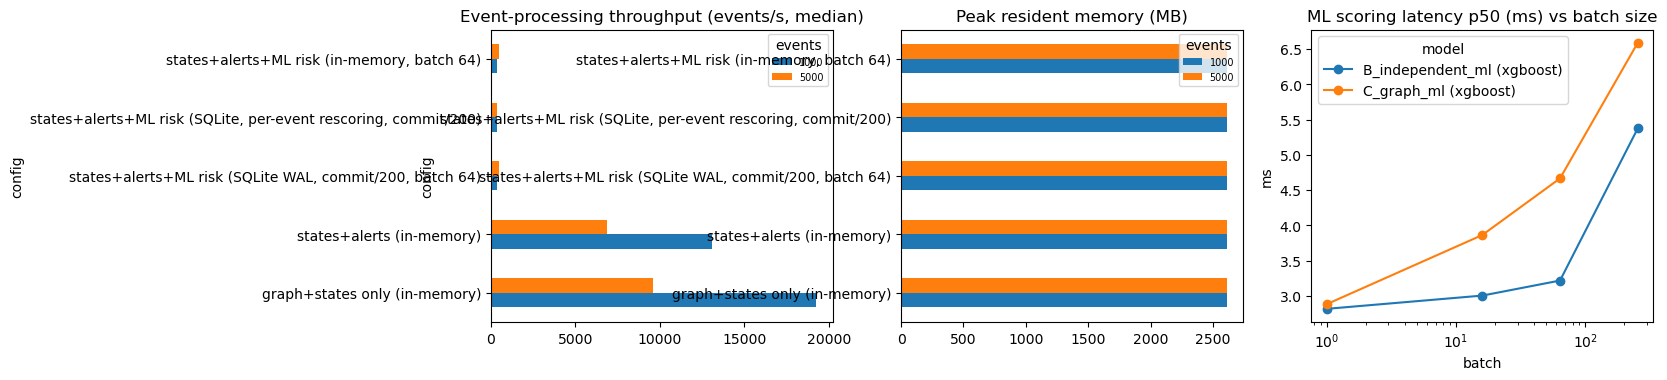

In [49]:
import platform as _pl
bench_out = {"host": {k: slim[k] for k in ("uname_m", "byteorder", "nproc", "memory_total_gb", "hypervisor", "python")}, "ml_latency": mlat.to_dict("records"), "ml_concurrency": conc.to_dict("records"), "llm": llm_b,
             "llm_concurrency": lconc.to_dict("records"), "throughput": agg.to_dict("records"), "queue": qrows, "nnpa_matmul": mm, "nnpa_probe": nn, "mode": MODE}
Path("results/benchmarks.json").write_text(json.dumps(bench_out, indent=2, default=str))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
a2 = agg.pivot(index="config", columns="workload_events", values="events_per_s"); a2.plot(kind="barh", ax=ax[0]); ax[0].set_title("Event-processing throughput (events/s, median)"); ax[0].legend(title="events", fontsize=7)
a3 = agg.pivot(index="config", columns="workload_events", values="peak_rss_mb"); a3.plot(kind="barh", ax=ax[1]); ax[1].set_title("Peak resident memory (MB)"); ax[1].legend(title="events", fontsize=7)
mlat.pivot(index="batch", columns="model", values="latency_ms_p50").plot(ax=ax[2], marker="o"); ax[2].set_xscale("log"); ax[2].set_title("ML scoring latency p50 (ms) vs batch size"); ax[2].set_ylabel("ms")
plt.tight_layout(); viz.save(fig, cfg, "benchmarks"); plt.show()

## 17. Interactive live demonstration

**Required scenario (synthetic patient):** discharged with (1) a laboratory test within 48 h, (2) physician result review, (3) conditional patient notification, (4) a follow-up appointment.
The test completes, but the acknowledgment evidence is **delayed**. The system recognises the dependency chain, separates *completed* from *unverified*, updates the forecast risk as events stream in, raises an evidence-grounded alert,
shows the graph and timeline, **reconciles the state when the delayed acknowledgment is finally documented**, and keeps the full audit trail. The same engine, models and rules as the experiments are used (streaming inference at every event).

In [50]:
from src.visualization_demo import LiveDemo, audit_table, alert_feed_html, plot_patient_journey, plot_evidence_graph, plot_risk_monitor
from src.scenario_lab import demo_events, DEMO_TEXT
live_scorers = {"B_independent_ml": scorers["B_independent_ml"], "C_graph_ml": scorers["C_graph_ml"]}
evs = demo_events("delayed_ack"); demo = LiveDemo(cfg, live_scorers, evs, PID)
idx = {e["event_id"]: i + 1 for i, e in enumerate(evs)}
print("scripted deliveries (ingest order):"); display(pd.DataFrame([{"#": i + 1, "event_type": e["event_type"], "obligation": e["obligation_id"].split(":")[-1], "event_time": e["event_time_utc"], "ingest_time": e["ingest_time_utc"]} for i, e in enumerate(evs)]))

scripted deliveries (ingest order):


,#,event_type,obligation,event_time,ingest_time
0,1,obligation_created,ob0,2024-03-04T09:00:00Z,2024-03-04T09:00:05Z
1,2,obligation_created,ob1,2024-03-04T09:00:00Z,2024-03-04T09:00:05Z
2,3,obligation_created,ob2,2024-03-04T09:00:00Z,2024-03-04T09:00:05Z
3,4,obligation_created,ob3,2024-03-04T09:00:00Z,2024-03-04T09:00:05Z
4,5,reminder_sent,ob0,2024-03-05T09:00:00Z,2024-03-05T09:00:30Z
5,6,lab_collected,ob0,2024-03-05T15:00:00Z,2024-03-05T15:00:30Z
6,7,result_posted,ob0,2024-03-05T21:00:00Z,2024-03-05T21:00:30Z
7,8,result_opened,ob1,2024-03-06T03:00:00Z,2024-03-06T03:00:30Z
8,9,task_status_snapshot,ob1,2024-03-09T10:00:00Z,2024-03-09T10:00:30Z
9,10,result_acknowledged,ob1,2024-03-08T13:00:00Z,2024-03-10T15:00:00Z


=== frame after 7/13 deliveries (service clock 2024-03-05T21:00:30Z) ===


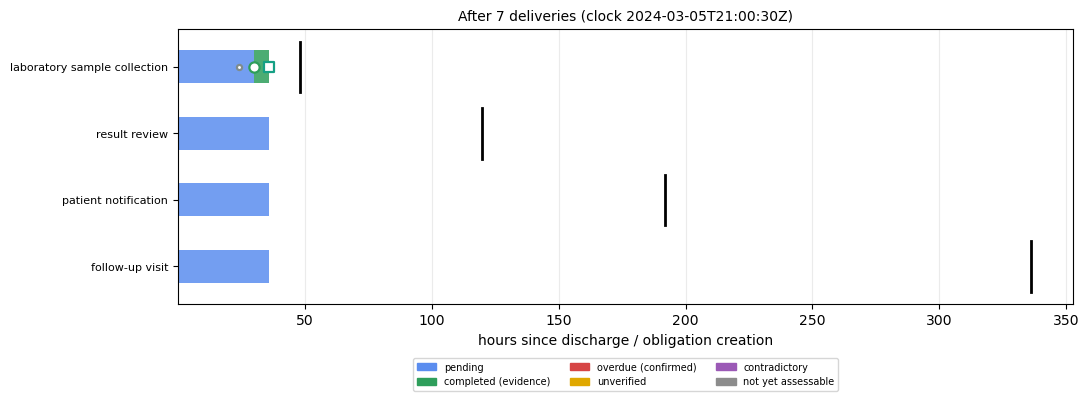

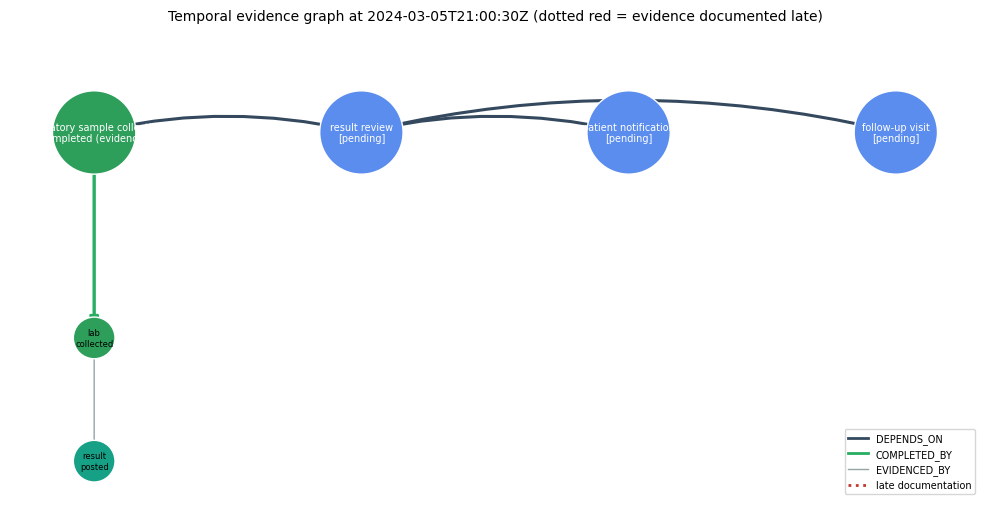

,obligation,state,risk(C)
0,ob0,completed_with_evidence,0.77
1,ob1,pending,0.38
2,ob2,pending,0.61
3,ob3,pending,0.61


=== frame after 9/13 deliveries (service clock 2024-03-09T10:00:30Z) ===


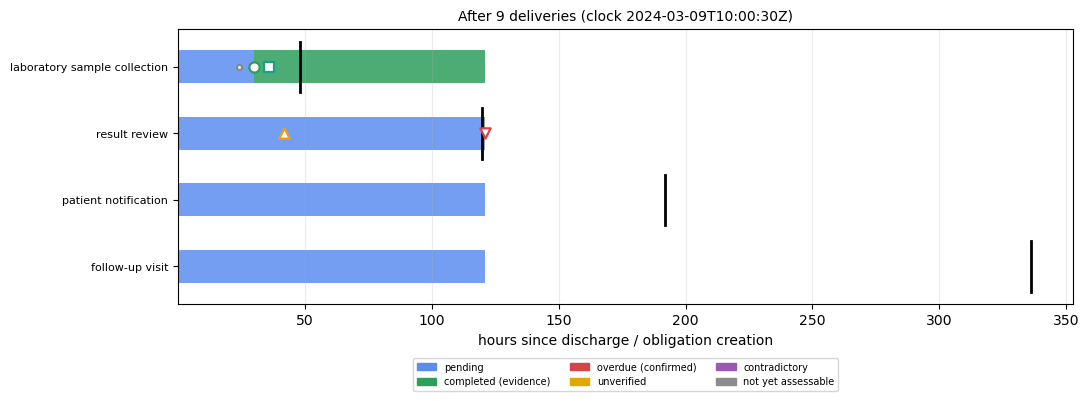

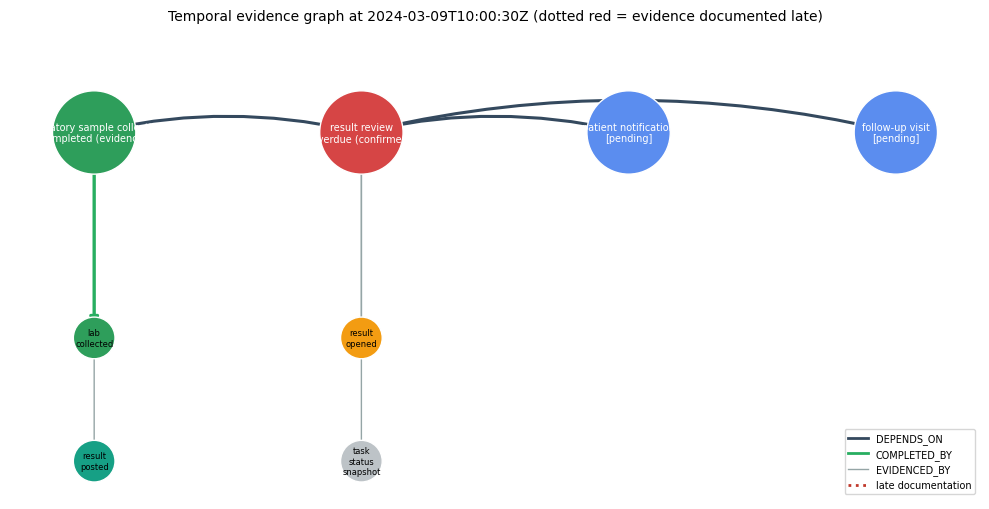

,obligation,state,risk(C)
0,ob0,completed_with_evidence,0.77
1,ob1,overdue_without_verified_completion,0.96
2,ob2,pending,0.88
3,ob3,pending,0.77


=== frame after 10/13 deliveries (service clock 2024-03-10T15:00:00Z) ===


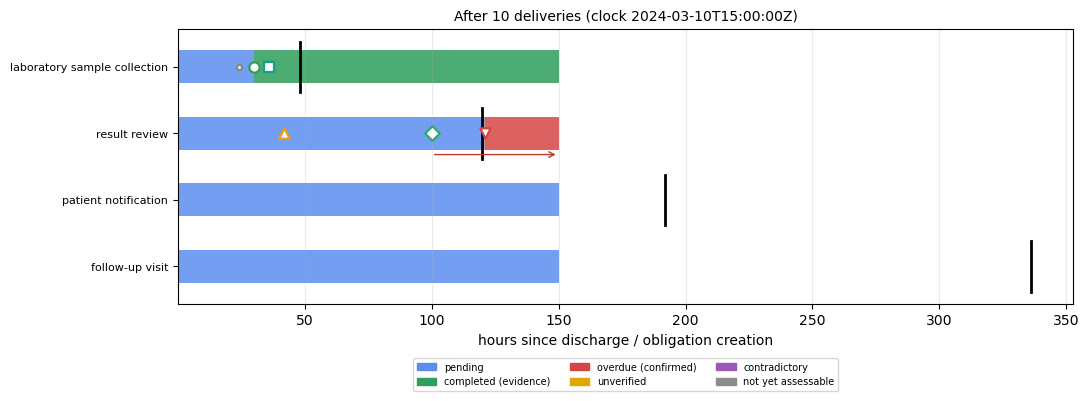

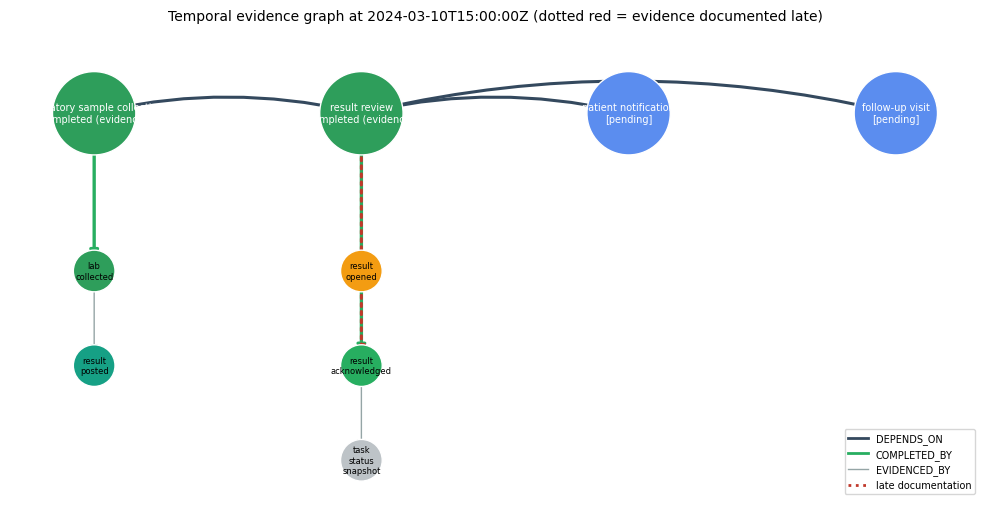

,obligation,state,risk(C)
0,ob0,completed_with_evidence,0.77
1,ob1,completed_with_evidence,0.96
2,ob2,pending,0.84
3,ob3,pending,0.77


=== frame after 13/13 deliveries (service clock 2024-03-16T21:00:30Z) ===


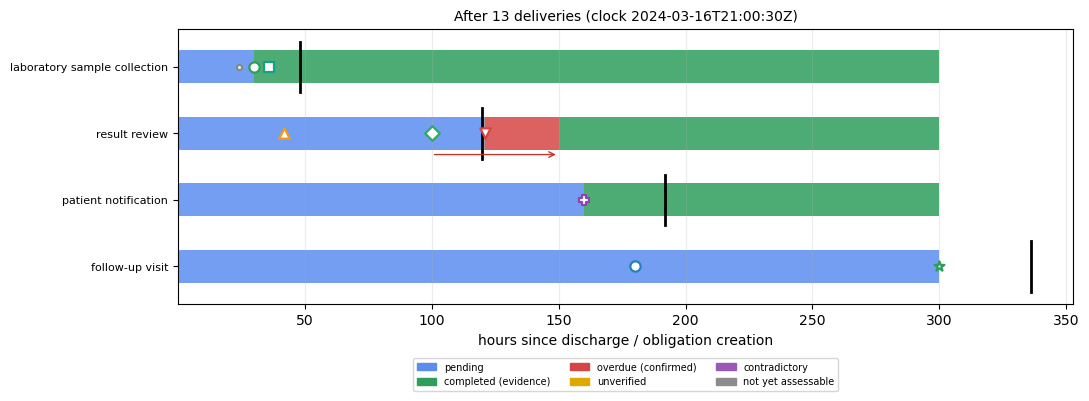

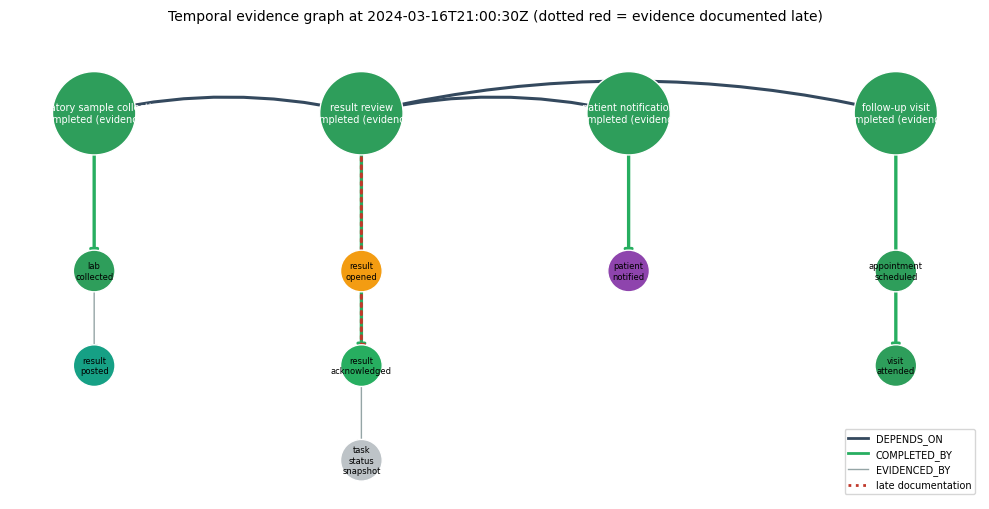

,obligation,state,risk(C)
0,ob0,completed_with_evidence,0.77
1,ob1,completed_with_evidence,0.96
2,ob2,completed_with_evidence,0.84
3,ob3,completed_with_evidence,0.85


In [51]:
steps = sorted({7, 9, 10, len(evs)})
for k, p, fj, fg in demo.storyboard(steps, with_graph=True):
    print(f"=== frame after {k}/{len(evs)} deliveries (service clock {iso(p.clock)}) ===")
    display(fj); display(fg); plt.close(fj); plt.close(fg)
    display(pd.DataFrame([{"obligation": o.split(":")[-1], "state": p.graph.derive_state(o, p.clock, live=True).state.value, "risk(C)": round((p.last_risk.get(o) or {}).get("C_graph_ml", float("nan")), 2)} for o in sorted(p.graph.obs)]))
    display(HTML(alert_feed_html(p, PID, last=4)))

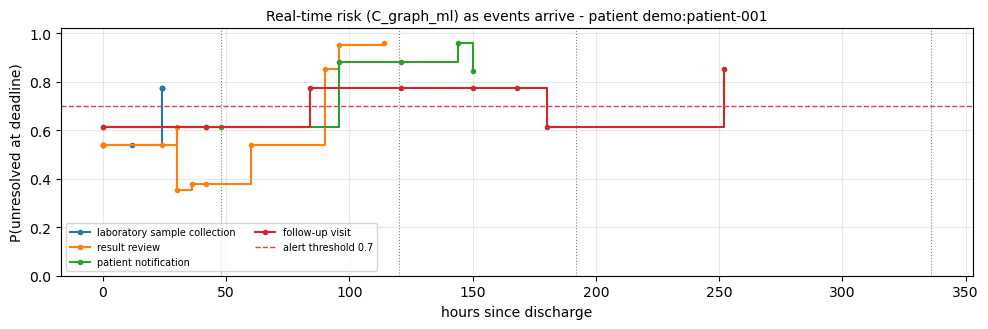

AUDIT TRAIL (every state change with event time/ingest time, rule and evidence):


,t_ingest,step,old_state,new_state,rule,trigger_event_id,evidence
0,2024-03-04T09:00:05Z,lab_collected,None,pending,R4_before_deadline_no_completion,demo:ob0:created,[]
1,2024-03-04T09:00:05Z,result_reviewed,None,pending,R4_before_deadline_no_completion,demo:ob1:created,[]
2,2024-03-04T09:00:05Z,patient_notified,None,pending,R4_before_deadline_no_completion,demo:ob2:created,[]
3,2024-03-04T09:00:05Z,followup_visit_completed,None,pending,R4_before_deadline_no_completion,demo:ob3:created,[]
4,2024-03-05T15:00:30Z,lab_collected,pending,completed_with_evidence,R1_own_verified_completion_evidence,demo:e02,[demo:e02]
5,2024-03-09T09:00:01Z,result_reviewed,pending,censored_not_yet_assessable,R6_deadline_passed_awaiting_late_evidence,timer:deadline,[]
6,2024-03-09T10:00:30Z,result_reviewed,censored_not_yet_assessable,overdue_without_verified_completion,R5_deadline_passed_open_confirmed,demo:e06,[demo:e06]
7,2024-03-10T15:00:00Z,result_reviewed,overdue_without_verified_completion,completed_with_evidence,R1_own_verified_completion_evidence,demo:e05,[demo:e05]
8,2024-03-11T01:00:30Z,patient_notified,pending,completed_with_evidence,R1_own_verified_completion_evidence,demo:e07,[demo:e07]
9,2024-03-16T21:00:30Z,followup_visit_completed,pending,completed_with_evidence,R1_own_verified_completion_evidence,demo:e09,[demo:e09]


final alert feed (newest first):


RECONCILIATION VERIFIED: review obligation went overdue_without_verified_completion -> completed_with_evidence when the delayed acknowledgment arrived; late flag = False


In [52]:
fin = demo.run_to(len(evs)); fin.finalize()
fig = plot_risk_monitor(fin, PID, "C_graph_ml"); viz.save(fig, cfg, "demo_risk_monitor"); plt.show()
print("AUDIT TRAIL (every state change with event time/ingest time, rule and evidence):"); display(audit_table(fin, PID))
print("final alert feed (newest first):"); display(HTML(alert_feed_html(fin, PID, last=10)))
ob1 = [t for t in fin.transitions if t["oid"] == "demo:ob1"]
assert [t["new_state"] for t in ob1][-2:] == ["overdue_without_verified_completion", "completed_with_evidence"], "delayed acknowledgment was not reconciled"
print("RECONCILIATION VERIFIED: review obligation went overdue_without_verified_completion -> completed_with_evidence when the delayed acknowledgment arrived; late flag =", fin.states["demo:ob1"][2])

variant: missing_ack -> {'ob0': 'completed_with_evidence', 'ob1': 'overdue_without_verified_completion', 'ob2': 'unverified_insufficient_evidence', 'ob3': 'overdue_without_verified_completion'}


variant: happy_path -> {'ob0': 'completed_with_evidence', 'ob1': 'completed_with_evidence', 'ob2': 'completed_with_evidence', 'ob3': 'completed_with_evidence'}


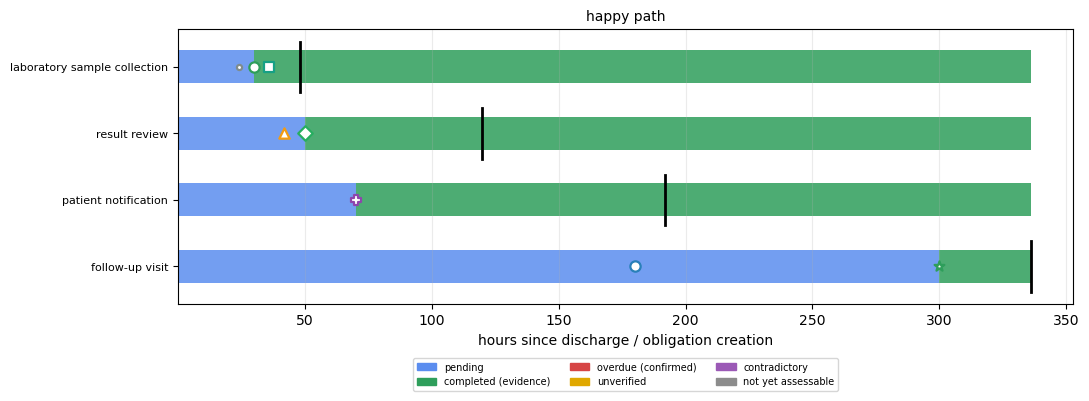

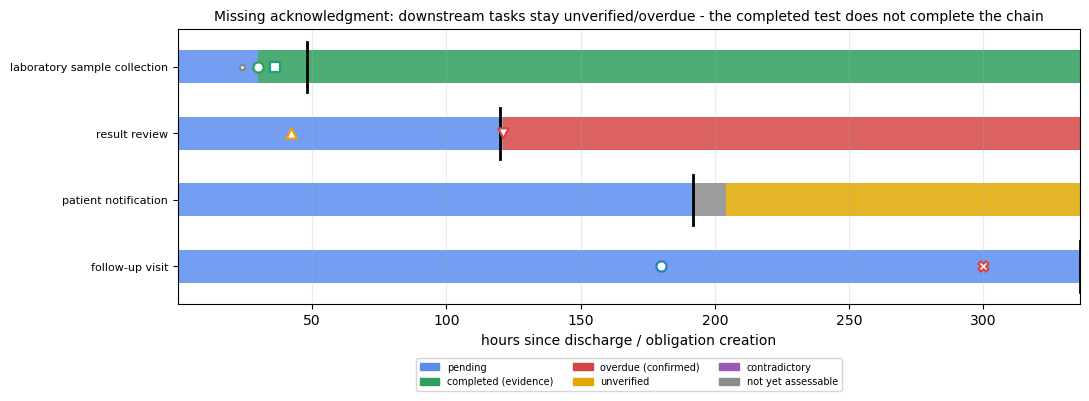

In [53]:
# variants: acknowledgment NEVER documented, and the happy path
for v in ("missing_ack", "happy_path"):
    d = LiveDemo(cfg, live_scorers, demo_events(v), PID); f = d.run_to(len(d.events)); f.finalize()
    print("variant:", v, "->", {o.split(":")[-1]: f.states[o][0].value + (" (late)" if f.states[o][2] else "") for o in sorted(f.states)})
fig = plot_patient_journey(f, PID, "happy path"); plt.show()
fm = LiveDemo(cfg, live_scorers, demo_events("missing_ack"), PID).run_to(99); fm.finalize()
fig = plot_patient_journey(fm, PID, "Missing acknowledgment: downstream tasks stay unverified/overdue - the completed test does not complete the chain"); plt.show()
display(HTML(alert_feed_html(fm, PID, last=6)))

In [54]:
# interactive widget (falls back to the static storyboard above when widgets cannot render, e.g. in a headless run)
try:
    import ipywidgets
    from IPython import get_ipython
    if get_ipython() is not None and os.environ.get("MEDRELAY_HEADLESS", "0") != "1":
        LiveDemo(cfg, live_scorers, demo_events("delayed_ack"), PID).widget()
    else:
        print("headless execution: interactive widget skipped; the storyboard frames above show the same states.")
except Exception as e:
    print("ipywidgets unavailable (", type(e).__name__, ") - using the static storyboard above")

headless execution: interactive widget skipped; the storyboard frames above show the same states.


In [55]:
display(HTML("<b>Performance monitor (measured on %s, mode=%s)</b>" % (hw["uname_m"], MODE)))
best_row = agg.sort_values("events_per_s", ascending=False).iloc[0]
display(pd.DataFrame({"metric": ["ML scoring latency p50 / p95 / p99, batch 1 (ms)", "ML scoring throughput, batch 256 (rows/s)", "event processing throughput, best config (events/s)", "LLM generation p50 / p95 (s)", "LLM tokens/s", "peak RSS, event workload (MB)", "queue event loss, block policy"],
                      "value": [" / ".join(f"{x:.1f}" for x in mlat[(mlat.model.str.startswith("C_")) & (mlat.batch == 1)][["latency_ms_p50", "latency_ms_p95", "latency_ms_p99"]].iloc[0]), f"{mlat[(mlat.model.str.startswith('C_')) & (mlat.batch == 256)].rows_per_s.iloc[0]:.0f}",
                                f"{best_row.events_per_s:.0f} ({best_row.config}, {best_row.workload_events} events)", f"{llm_b['latency_s']['p50']:.1f} / {llm_b['latency_s']['p95']:.1f}", f"{llm_b['tokens_per_s']['mean']:.1f}",
                                f"{agg.peak_rss_mb.max():.0f}", str(qrows[0]['event_loss']) + " / " + str(qrows[1]['event_loss'])]}))

,metric,value
0,"ML scoring latency p50 / p95 / p99, batch 1 (ms)",2.9 / 10.3 / 18.0
1,"ML scoring throughput, batch 256 (rows/s)",38861
2,"event processing throughput, best config (events/s)","19254 (graph+states only (in-memory), 1000 events)"
3,LLM generation p50 / p95 (s),9.5 / 9.9
4,LLM tokens/s,9.2
5,"peak RSS, event workload (MB)",2611
6,"queue event loss, block policy",0 / 0


## 18. Results, limitations and final conclusions

In [56]:
import json as _j
def load(n): return _j.loads(Path(f"results/{n}.json").read_text())
mA = A_res["comparison"].sort_values("val_macro_f1", ascending=False).iloc[0]
cB = B_res["comparison"]; bC = cB[cB.features == "C_graph"].sort_values("val_pr_auc", ascending=False).iloc[0]; bB = cB[cB.features == "B_independent"].sort_values("val_pr_auc", ascending=False).iloc[0]
mC_ = load("model_c_summary"); cC = pd.DataFrame(mC_["comparison"]).sort_values("val_pr_auc", ascending=False).iloc[0]
r1 = E1["table"]; ew24 = ew[(ew.min_lead_h == 24.0) & (ew["target_recall(val)"] == 0.7)].set_index("system")
summary = pd.DataFrame([
    ["Action classification (silver labels)", f"{mA.model} macro-F1 {mA.test_macro_f1:.3f} / micro-F1 {mA.test_micro_f1:.3f} (test); developer-annotated spans: accuracy {mA.challenge_span_accuracy:.3f}"],
    ["Follow-up risk (simulated outcomes)", f"best graph model {bC.model}: PR-AUC {bC.test_pr_auc:.3f} [{bC.test_pr_auc_ci_lo:.3f},{bC.test_pr_auc_ci_hi:.3f}], ROC-AUC {bC.test_roc_auc:.3f}, Brier {bC.test_brier:.3f}, ECE {bC.test_ece:.3f}; independent-task {bB.model}: PR-AUC {bB.test_pr_auc:.3f}"],
    ["No-show (real data, secondary)", f"{cC.model}: PR-AUC {cC.test_pr_auc:.3f} (prevalence {cC.prevalence:.3f}), ROC-AUC {cC.test_roc_auc:.3f}, ECE {cC.test_ece:.3f}"],
    ["GenAI extraction (350M)", "typed F1 B/C2/E on challenge set: " + " / ".join(f"{r1[(r1.extractor == x) & (r1.corpus == 'developer_annotated_challenge')].typed_f1.iloc[0]:.2f}" for x in ('B_llm_raw', 'C2_llm_validated_filled', 'E_rules_plus_llm')) + f"; rules A {r1[(r1.extractor == 'A_rules') & (r1.corpus == 'developer_annotated_challenge')].typed_f1.iloc[0]:.2f}"],
    ["Early warning (>=24h lead, recall target 0.7 on val)", " | ".join(f"{s}: recall {ew24.loc[s,'recall']:.2f}, FAR {ew24.loc[s,'false_alert_rate']:.2f}, lead {ew24.loc[s,'median_lead_h']:.0f}h" for s in ("A_reminder_24h", "A_deadline_only", "B_independent_ml", "C_graph_ml"))],
    ["State correctness at t*", f"engine {se['engine_evidence_aware']['accuracy']:.3f} (final after reconciliation {se['engine_final_after_reconciliation']['accuracy']:.3f}) vs naive absence=failure {se['naive_absence_is_failure']['accuracy']:.3f}"],
    ["Throughput (best config)", f"{best_row.events_per_s:.0f} events/s on {hw['uname_m']} ({hw['nproc']} vCPU)"]], columns=["result", "measured value"])
display(summary); summary.to_csv("results/final_summary.csv", index=False)
print("notebook wall time: %.1f min | mode=%s | host=%s" % ((time.time() - T_NB0) / 60, MODE, hw["uname_m"]))

,result,measured value
0,Action classification (silver labels),svm macro-F1 0.707 / micro-F1 0.849 (test); developer-annotated spans: accuracy 0.288
1,Follow-up risk (simulated outcomes),"best graph model xgboost/C_graph: PR-AUC 0.830 [0.778,0.889], ROC-AUC 0.763, Brier 0.194, ECE 0...."
2,"No-show (real data, secondary)","hgb/with_demographics: PR-AUC 0.354 (prevalence 0.201), ROC-AUC 0.736, ECE 0.016"
3,GenAI extraction (350M),typed F1 B/C2/E on challenge set: 0.38 / 0.43 / 0.70; rules A 0.74
4,"Early warning (>=24h lead, recall target 0.7 on val)","A_reminder_24h: recall 1.00, FAR 0.12, lead 24h | A_deadline_only: recall 1.00, FAR 0.19, lead 3..."
5,State correctness at t*,engine 0.903 (final after reconciliation 0.997) vs naive absence=failure 0.884
6,Throughput (best config),19254 events/s on s390x (2 vCPU)


notebook wall time: 12.2 min | mode=fast | host=s390x


### Interpretation, limitations and honest conclusions

* **Research question (simulated processes only).** The tables above quantify, with patient-grouped bootstrap intervals, whether dependency-aware graph features improve *early* warning over independent-task monitoring. Read the lead-restricted rows
  (>= 24 h / 72 h before the deadline): a deadline-only rule is hard to beat *late* in the window (it only fires once most of the window has elapsed), so any advantage of the graph approach is an *early-warning* advantage; see the confidence intervals before
  concluding anything, and note when an interval includes zero.
* **Labels.** Risk and state outcomes come from a **seeded simulator** whose causal structure we know; scores say how well the pipeline recovers that structure, **not** how it would perform on real hospital data. Hidden generator profiles are used only for post-hoc error analysis.
* **No gold annotations.** Action labels are rule-proposed; extraction evaluation uses a *developer-annotated* challenge set and synthetic-by-construction documents. Independent clinician review is the single most valuable missing piece.
* **GenAI.** The 350M Granite model is too weak to extract obligations on its own; validation removes fabricated fields but cannot add missing obligations. The ensemble with rules is the best measured GenAI-involving strategy; the 1B model (smaller sample) is the measured upper bound. Latency is dominated by the LLM, so it is kept off the per-event path.
* **Hardware.** Section 2 states the architecture that executed this run; throughput/latency are for that VM (2 vCPU, ~4 GB). NNPA is *present* and was device-tested with zDNN matmul; the tree/linear models do **not** use it.
* **Not a medical device.** All recommendations are for qualified human review; nothing here modifies orders, prescriptions, diagnoses or treatment.